---
title: Hidden Markov Model with Control (Part 4)
subtitle: Control a Roomba using Active Inference and RxInfer
author: Kobus Esterhuysen
date: '2024-05-24'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - RxInfer
  - Julia
image: HMMwithControl.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [ ]:
#| hide
# BASED ON
  # HMMwithControl3_PORT^v2.ipynb
    
# DONE
# v1 starts ------------------------------------------------
# add control

# TODO
# clean for publication

# Hidden Markov Model with Control (Part 4)
## 1 BUSINESS UNDERSTANDING

This is the fourth part of an effort to add control to the *Hidden Markov Model* RxInfer example. Eventually this work will be used in a more elaborate scheduling project making use of active inference.

In the previous parts, the Roomba moved through a 3-room apartment, consisting of a bedroom, a living room, and a bathroom, at random, and the agent only watched: it inferred which room the Roomba was in (Parts 1 and 2) and whether that room was occupied by a person (Part 3). In this part, the agent takes control. At each time step, it chooses where the Roomba goes next, and it does so with a goal in mind: **to clean where it does not disturb anyone**, i.e. to prefer rooms that are not occupied.

The Roomba keeps its three sensors from Part 3:

- a camera that recognizes the floor texture (hardwood in the bedroom, carpet in the living room, tiles in the bathroom),
- a light sensor that measures the light intensity (the living room has skylights and is usually bright, the bathroom has no windows and is usually dark, and the bedroom is in between), and
- a motion sensor that detects movement, the most direct evidence that a person is present.

As in Part 3, room and occupancy are combined into a single state factor with six values: each room, either empty or occupied.

In active inference, a goal is expressed as a *preference over observations*: the agent prefers to observe what it wants to be true. Here, the agent prefers to observe *no motion*. It cannot see whether a room is occupied, but it can choose actions that it expects to lead to quiet rooms. To choose, the agent looks a few steps ahead: for each candidate sequence of moves, it predicts where the Roomba will end up and what it will observe there, and it scores the sequence by its *expected free energy*. This score balances two things: reaching preferred observations (no motion), and reducing uncertainty about the state, e.g. checking whether a room is occupied before settling in it.

The new ingredients are:

- **actions**: in each time step, the Roomba either stays where it is or moves towards one of the other rooms. The transition matrix now has one version per action, describing where each move is likely to take the Roomba, while occupancy keeps changing as in Part 3,
- **preferences**: a preference for *no motion*, encoded in a preference vector for the motion sensor, and
- **an online loop**: the agent and the environment now interact step by step. The agent observes, updates its beliefs, chooses an action, and the environment responds.

To keep the focus on control, the agent is given its model of the world, i.e. its observation matrices and its transition matrices, rather than learning them as in the previous parts.

This interaction fills in the remaining functions of the usual structure:

- `create_envir()`
    - `execute()`: carries out the chosen action, moving the Roomba and updating occupancy
    - `observe()`
    - `state()` (true state, for evaluation only)
- `create_agent()`
    - `act()`: returns the chosen action
    - `future()`: predicts future states and observations for the candidate actions
    - `compute()`: infers the current state and evaluates the candidate actions
    - `slide()`: moves the agent's time window one step forward

As in the previous parts, and as in the active inference literature, $\mathbf{A}$ holds the observation (likelihood) matrices and $\mathbf{B}$ the state transition matrices, swapped compared to the original RxInfer example, which follows the engineering convention of using $A$ for state transitions.

In [2]:
versioninfo() ## Julia version

Julia Version 1.12.7
Commit 6d172b025e4 (2026-08-15 08:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 12 virtual cores)


In [3]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots"))
Pkg.add(Pkg.PackageSpec(;name="XLSX"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools"))
Pkg.add(Pkg.PackageSpec(;name="Distributions"))
Pkg.add(Pkg.PackageSpec(;name="OffsetArrays"))

using RxInfer, Random, BenchmarkTools, Distributions, Plots, XLSX, DataFrames, OffsetArrays

     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/envir

In [4]:
Pkg.status()

Status `~/.julia/environments/v1.12/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [a93c6f00] DataFrames v1.8.2
  [31c24e10] Distributions v0.25.131
  [6fe1bfb0] OffsetArrays v1.17.0
  [91a5bcdd] Plots v1.41.7
  [86711068] RxInfer v5.5.2
  [fdbf4ff8] XLSX v0.13.1
  [9a3f8284] Random v1.11.0


In [5]:
## tuple0(x...): build a 0-based tuple (x^{[0]}, ..., x^{[N]}), mirroring the math.
##   - each argument becomes one entry: tuple0(v) wraps v; it never re-indexes v itself
##   - the index range 0:N is derived from the number of arguments
##   - entries may differ in shape, e.g. likelihood matrices for different modalities
## Returns an OffsetVector (mutable), not a Julia Tuple.
tuple0(x...) = OffsetVector(collect(x), 0:length(x)-1)

## offset0(v): re-index an existing vector from 0, e.g. a trajectory over t = 0, ..., T.
## Unlike tuple0, it does not wrap v; it shifts v's own indices.
offset0(v) = OffsetVector(v, 0:length(v)-1)

offset0 (generic function with 1 method)

**Why `tuple0()` rather than `OffsetVector()` directly?**

1. **It prevents a level mix-up.** With `OffsetVector`, it is easy to offset the *wrong level*:

```julia
    OffsetVector([1.0, 0.0, 0.0], 0:2)    ## the one-hot vector itself, re-indexed 0:2 (wrong level)
    OffsetVector([[1.0, 0.0, 0.0]], 0:0)  ## a tuple containing the one-hot vector (intended)
    tuple0([1.0, 0.0, 0.0])               ## the same as the second line, with no way to get it wrong
```

    The first line is valid code but means something else: the one-hot vector $\hat{\boldsymbol{s}}^{\ast[0,0]}$ itself, now indexed from 0, rather than the tuple $\hat{\mathbf{s}}^{\ast(0)} = \big(\hat{\boldsymbol{s}}^{\ast[0,0]}\big)$. Nothing would complain, and later code that indexes `[0]` would get a single number instead of a vector. `tuple0` always wraps its arguments as *entries*, so this mistake cannot happen.

2. **The index range is computed automatically.** With `OffsetVector`, the range is written by hand and has to agree with the number of entries: adding a second modality to `LAˣ` while forgetting to change `0:0` to `0:1` gives an error at best. `tuple0` derives the range from the number of arguments, so adding or removing an entry is a one-line change.

3. **It reads like the math.** `tuple0(A0, A1)` looks like $\big(\boldsymbol{A}^{[0]}, \boldsymbol{A}^{[1]}\big)$: entries separated by commas, nothing else. `OffsetVector([A0, A1], 0:1)` adds square brackets and a range that have nothing to do with the math.

4. **It states the intent.** `OffsetVector` says "an array with shifted indices", which could be anything. `tuple0` says "a tuple of factors or modalities, as in the math", the specific concept from (10.33). And since all tuples are built the same way, a search for `tuple0(` finds every one of them.

5. **There is one place to change things.** Changing how tuples work, e.g. switching to an immutable 0-based type, or adding a check that every column of every $\boldsymbol{A}$ and $\boldsymbol{B}$ sums to 1, means changing one line instead of every place a tuple is built.

6. **Entries of different shapes just work.** `collect` builds a vector of whatever is passed in, so `tuple0(A0, A1)` with a $3\times 3$ and a $2\times 3$ matrix gives a vector of matrices, which is exactly what a tuple of likelihood matrices with different numbers of observations needs.

## 2 DATA UNDERSTANDING

The data is simulated, but unlike in the previous parts, it is not generated in advance: it arises from the interaction between the agent and the environment. At each tick, the agent observes, chooses an action, and the environment responds, so the Roomba's path depends on the agent's choices. A run covers $T + 1 = 600$ ticks, $t = 0, \ldots, T$, and records three kinds of one-hot encoded vectors:

- **Observations**, which the agent receives: the observation tuple $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)$, with one entry per sensor:
    - $\hat{\boldsymbol{o}}^{[t,0]}$ (Texture) over $\{\text{hardwood}, \text{carpet}, \text{tiles}\}$
    - $\hat{\boldsymbol{o}}^{[t,1]}$ (Light) over $\{\text{low}, \text{high}\}$
    - $\hat{\boldsymbol{o}}^{[t,2]}$ (Motion) over $\{\text{no motion}, \text{motion}\}$
- **Actions**, which the agent chooses: the action tuple $\hat{\mathbf{u}}^{(t)} = \big(\hat{\boldsymbol{u}}^{[t,0]}\big)$, whose entry $\hat{\boldsymbol{u}}^{[t,0]}$ is over the room the Roomba heads for: $\{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$. Heading for the room it is already in means staying put. The action chosen at tick $t$ takes effect at tick $t+1$, so actions are recorded for $t = 0, \ldots, T-1$.
- **True states**, which the agent never sees: the state tuple $\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast[t,0]}\big)$, whose entry $\hat{\boldsymbol{s}}^{\ast[t,0]}$ (RoomOccupancy) is over the six combinations of room and occupancy: $\{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

In each one-hot vector, the component that is 1 marks the value that occurred: for $\hat{\boldsymbol{s}}^{\ast[t,0]}$, the room the Roomba is actually in and whether a person is in it; for $\hat{\boldsymbol{o}}^{[t,0]}$, $\hat{\boldsymbol{o}}^{[t,1]}$ and $\hat{\boldsymbol{o}}^{[t,2]}$, the texture, light intensity and motion the sensors report; for $\hat{\boldsymbol{u}}^{[t,0]}$, the room the agent chose to head for.

The agent works with the observations only, and with the actions it chose itself. The true states are kept for evaluation: they let us check how well the agent's inferred room and occupancy match the real situation, and, new in this part, how often the Roomba actually ended up in an occupied room.

## 3 DATA PREPARATION

As in the previous parts, we use the data from the simulation directly; no cleaning or transformation is needed. What changes in this part is *when* the data becomes available. The data is no longer a complete time series handed to the agent at once: at each tick, the agent receives only the current observation tuple $\hat{\mathbf{o}}^{(t)}$, updates its beliefs, and chooses its next action. There is therefore no separate preparation step before inference; the agent processes the data as it arrives.

Throughout this notebook, trajectories are indexed from 0, so that index $t$ always means time $t$. During a run, we record four trajectories, each re-indexed from 0 with `offset0`:

- `Lôː`: the received observation tuples $\hat{\mathbf{o}}^{(0:T)}$,
- `Lûː`: the chosen action tuples $\hat{\mathbf{u}}^{(0:T-1)}$,
- `Lsː`: the agent's beliefs about the state at each tick, i.e. its posterior over the six combinations of room and occupancy, and
- `Lŝˣː`: the true state tuples $\hat{\mathbf{s}}^{\ast(0:T)}$, for evaluation only.

Wherever the agent hands data to `RxInfer`, the boundary conversion from the previous parts still applies: `RxInfer` works with ordinary vectors indexed from 1, so data going in is converted with `parent`, and results coming out are re-indexed with `offset0`. In this part, this happens inside the agent, at each tick, rather than once for the whole data set.

From the agent's joint belief, its belief about the room and about occupancy follow by adding up the right entries, as shown in the evaluation.

## 4 MODELING
### 4.1 Narrative
In general, we will have the following symbol conventions. They are shown for states $s$; observations $o$ and actions $u$ follow the same pattern.

**Indices.** Time-only indices are written in $(\,)$, compound or non-time indices in $[\,]$. The index therefore tells you what kind of object you are looking at: a superscript $(t)$ collects everything at time $t$, while $[t,n]$ picks out a single state factor $n$ at time $t$.

- $t$: time step, $t = 0, \ldots, T$
- $s^{[t,n]}$: categorical random variable for state factor $n$ at time $t$. Its values are labels. In this part there is a single state factor, RoomOccupancy, whose six values combine the room with whether it is occupied: $\{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$. It is not bold, because a single categorical random variable has no structure.
- $\mathbf{s}^{(t)} = \big(s^{[t,0]}, \ldots, s^{[t,N]}\big)$: tuple of the random variables of all state factors at time $t$
- $u^{[t,0]}$: categorical random variable for the action at time $t$, i.e. the room the Roomba heads for: $\{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$. Heading for the room it is already in means staying put. The action at time $t$ takes effect at time $t+1$.

**Fonts.** Bold marks anything with structure, and the style of bold tells you which kind:

- upright bold ($\mathbf{s}$, $\mathbf{A}$): a *tuple*, an ordered collection whose entries may differ in size, such as one entry per state factor or observation modality
- italic bold ($\boldsymbol{s}$, $\boldsymbol{A}$): a single *vector*, *matrix* or *array*, such as a one-hot vector, a probability vector, a belief, or a likelihood matrix

For example, $\mathbf{A} = \big(\boldsymbol{A}^{[0]}, \ldots, \boldsymbol{A}^{[M]}\big)$ is the tuple of likelihood matrices, and $\boldsymbol{A}^{[m]}$ is the matrix for observation modality $m$. Likewise, $\mathbf{B} = \big(\boldsymbol{B}^{[0]}, \ldots, \boldsymbol{B}^{[N]}\big)$ and $\mathbf{D} = \big(\boldsymbol{D}^{[0]}, \ldots, \boldsymbol{D}^{[N]}\big)$ collect one array per state factor, and $\mathbf{C} = \big(\boldsymbol{C}^{[0]}, \ldots, \boldsymbol{C}^{[M]}\big)$ collects one preference vector per observation modality. Upright bold is only used for Latin letters, because Greek letters such as $\pi$ do not render in upright bold.

**Marks.** A hat marks a *realized* value: something that has actually happened. A bold symbol without a hat is a *distribution*: a probability vector over possible values.

- $\hat{\boldsymbol{s}}^{[t,n]}$: realized value of $s^{[t,n]}$, one-hot encoded as a vector, e.g. $[0,0,0,1,0,0]^{\top}$ for livingroom-occupied
- $\hat{\mathbf{s}}^{(t)} = \big(\hat{\boldsymbol{s}}^{[t,0]}, \ldots, \hat{\boldsymbol{s}}^{[t,N]}\big)$: tuple of the realized values of all state factors at time $t$
- $\hat{\mathbf{s}}^{(0:T)} = \big(\hat{\mathbf{s}}^{(0)}, \ldots, \hat{\mathbf{s}}^{(T)}\big)$: trajectory (sequence over time) of realized states
- $\hat{\boldsymbol{u}}^{[t,0]}$: the action the agent actually chose at time $t$, one-hot encoded, e.g. $[0,0,1]^{\top}$ for heading to the bathroom; $\hat{\mathbf{u}}^{(t)} = \big(\hat{\boldsymbol{u}}^{[t,0]}\big)$ is the tuple of all actions at time $t$
- $\boldsymbol{s}^{[t,n]}$, without a hat: the agent's *belief* about state factor $n$ at time $t$, a probability vector with one entry per value of $s^{[t,n]}$
- $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, u]\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$: a probability vector (here, over the next room and occupancy, given action $u$), not a realized value
- $\bar{\boldsymbol{A}}^{[m]}$, with a bar: a *posterior mean*, the agent's point estimate of a learned matrix after inference (used in the previous parts; in this part, the agent's matrices are given)

Because room and occupancy share one state factor, the agent's belief about each of them follows by adding up entries of $\boldsymbol{s}^{[t,0]}$: its belief that the Roomba is in the bedroom is the sum of the entries for bedroom-empty and bedroom-occupied, and its belief that the current room is occupied is the sum of the three *occupied* entries.

The agent never observes the states, so its state variables never carry a hat: it has random variables $s^{[t,n]}$ and beliefs $\boldsymbol{s}^{[t,n]}$. The observations are different, because the agent does receive them. Each observation therefore appears in three forms, which share the same index but are different objects:

- $o^{[t,0]}$: the categorical random variable for the Texture observation at time $t$, with values $\{\text{hardwood}, \text{carpet}, \text{tiles}\}$
- $\hat{\boldsymbol{o}}^{[t,0]}$: the observation the agent actually *received*, one-hot encoded. If the camera reads hardwood at time $t$, then $\hat{\boldsymbol{o}}^{[t,0]} = [1,0,0]^{\top}$. If at the same time the light sensor reads high and the motion sensor detects motion, then $\hat{\boldsymbol{o}}^{[t,1]} = [0,1]^{\top}$ and $\hat{\boldsymbol{o}}^{[t,2]} = [0,1]^{\top}$, and the tuple of all modalities is $\hat{\mathbf{o}}^{(t)} = \big([1,0,0]^{\top}, [0,1]^{\top}, [0,1]^{\top}\big)$.
- $\boldsymbol{o}^{[t,0]}$, without a hat: an *expected* observation, i.e. a probability vector the agent computes from its beliefs, $\boldsymbol{o}^{[t,0]} = \boldsymbol{A}^{[0]}\,\boldsymbol{s}^{[t,0]}$

For example, suppose the agent believes the Roomba is most likely in the bedroom, and probably alone: $\boldsymbol{s}^{[t,0]} = [0.5, 0.2, 0.15, 0.05, 0.05, 0.05]^{\top}$ over the six joint states, i.e. bedroom 0.7, living room 0.2, bathroom 0.1, and occupied 0.3. Suppose also that its likelihood matrix $\boldsymbol{A}^{[0]}$ has the same values as $\boldsymbol{A}^{\ast[0]}$. Since the texture depends only on the room, each room's column appears twice, once for empty and once for occupied. Then it expects

$$
\boldsymbol{o}^{[t,0]} = \boldsymbol{A}^{[0]}\,\boldsymbol{s}^{[t,0]} =
\begin{bmatrix} 0.9 & 0.9 & 0.05 & 0.05 & 0.05 & 0.05 \\ 0.05 & 0.05 & 0.9 & 0.9 & 0.05 & 0.05 \\ 0.05 & 0.05 & 0.05 & 0.05 & 0.9 & 0.9 \end{bmatrix}
\begin{bmatrix} 0.5 \\ 0.2 \\ 0.15 \\ 0.05 \\ 0.05 \\ 0.05 \end{bmatrix}
=
\begin{bmatrix} 0.645 \\ 0.22 \\ 0.135 \end{bmatrix}
$$

that is, hardwood with probability 0.645, carpet 0.22, and tiles 0.135. If the camera then reads carpet, the received observation is $\hat{\boldsymbol{o}}^{[t,0]} = [0,1,0]^{\top}$: a single definite outcome, which the agent uses to update its belief $\boldsymbol{s}^{[t,0]}$ toward the living room. In the same way, the motion sensor's expected observation depends only on occupancy: with occupied 0.3, the agent expects motion with probability $0.05 \cdot 0.7 + 0.8 \cdot 0.3 = 0.275$.

So, for observations the agent has both hatted and unhatted forms: what it expects ($\boldsymbol{o}$) and what it gets ($\hat{\boldsymbol{o}}$). For states, it only ever has the unhatted forms: the random variable $s^{[t,n]}$ and the belief $\boldsymbol{s}^{[t,n]}$. Only the environment has $\hat{\boldsymbol{s}}^{\ast[t,n]}$, the room the Roomba is really in and whether a person is really there.

**Actions, preferences and planning.** With control, the agent needs three more kinds of objects:

- $\boldsymbol{B}^{[0]}[\bullet, \bullet, u]$: the transition matrix *under action* $u$. With actions, $\boldsymbol{B}^{[0]}$ becomes a 3-dimensional array, one $6 \times 6$ matrix per action: next state, previous state, action.
- $\boldsymbol{C}^{[m]}$: the agent's *preference* over the observations of modality $m$, a probability vector expressing which observations it prefers to receive. In this part, only the motion sensor has a real preference, for *no motion*, e.g. $\boldsymbol{C}^{[2]} = [0.9, 0.1]^{\top}$; the other modalities have flat preferences.
- planning symbols, following Algorithm 18 in Chapter 9:
    - $H$: the planning horizon, i.e. how many steps the agent looks ahead; $\tau = 0, \ldots, H-1$ counts the imagined steps, where step $\tau$ predicts time $t + \tau + 1$
    - $\boldsymbol{V}$: the matrix of candidate *policies*, i.e. action sequences. Row $p$, $\pi^{[p]} = \boldsymbol{V}[p, \bullet]$, is policy $p$, and $\boldsymbol{V}[p, \tau]$ is the action it prescribes at step $\tau$.
    - $\boldsymbol{s}_{\pi^{[p]}}^{[\tau,0]}$ and $\boldsymbol{o}_{\pi^{[p]}}^{[\tau,m]}$: the *predicted* belief and *predicted* observation at step $\tau$ under policy $p$, unhatted because they are predictions
    - $G^{[p,\tau]}$: the expected free energy of policy $p$ at step $\tau$, and $G^{[p]} = \sum_{\tau} G^{[p,\tau]}$ its total
    - $\pi^{(t)}$: the random variable for the policy chosen at time $t$, with posterior $Q\big(\pi^{(t)} = \pi^{[p]}\big) = \sigma\big(-\boldsymbol{G}\big)_p$, where $\boldsymbol{G}$ collects the $G^{[p]}$ and $\sigma$ is the softmax
    - $Q\big(u^{[t,0]}\big)$: the resulting distribution over the next action, obtained by adding up $Q\big(\pi^{(t)} = \pi^{[p]}\big)$ over all policies whose first action is $u$

**The asterisk** ${}^{\ast}$ marks what belongs to the environment (the generative process), e.g. $\hat{\mathbf{s}}^{\ast(t)}$ and $\boldsymbol{B}^{\ast[0]}$. Symbols without it belong to the agent (the generative model). In this part, the agent is given its matrices: $\boldsymbol{A}^{[m]} = \boldsymbol{A}^{\ast[m]}$ and $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$. The preferences $\mathbf{C}$ belong to the agent alone; the environment has none. The observation $\hat{\mathbf{o}}^{(t)}$ has no asterisk because it is shared: the environment generates it and the agent receives it. The same holds for the action $\hat{\mathbf{u}}^{(t)}$: the agent chooses it and the environment carries it out.

**Code symbols.** The code mirrors the math as closely as identifiers allow:

- `L` prefix: upright bold ($\mathbf{s}$, $\mathbf{A}$), a tuple. The `L` suggests verticality (upright).
- `_` prefix: italic bold ($\boldsymbol{s}$, $\boldsymbol{A}$), a single vector, matrix or array that is not part of a tuple. The `_` suggests the underline of bold.
- hat: a Unicode circumflex on the letter, e.g. `ŝ` for $\hat{s}$, `ô` for $\hat{o}$, `û` for $\hat{u}$
- bar: a combining macron on the letter (typed `\bar` then Tab), e.g. `_Ā⁰` for $\bar{\boldsymbol{A}}^{[0]}$
- asterisk ${}^{\ast}$: a superscript `ˣ` (typed `\^x` then Tab)
- time index $(t)$: a subscript in the name: `ₜ` for $t$, `ₜ₋₁` for $t-1$, `₀` for $t=0$
- trajectory $(0{:}T)$: a `ː` suffix (triangular colon), e.g. `Lôː` for $\hat{\mathbf{o}}^{(0:T)}$
- tuple index $[n]$ or $[m]$: real 0-based indexing, e.g. `LAˣ[0]`. In Julia, tuples over factors or modalities are built with `tuple0(a, b, ...)`, which wraps each argument as one entry. In Python, ordinary tuples and lists are already 0-based.
- trajectory index $t$: real 0-based indexing too, e.g. `Lŝˣː[t]`. In Julia, a trajectory is an existing vector re-indexed from 0 with `offset0(v)`, which shifts the vector's own indices instead of wrapping it.

**Indexing and the tear-off mnemonic.** Only tuples have names; their entries are written by indexing. Read a factor or modality index (`[n]` or `[m]`) as tearing the vertical line off the `L`, turning it into `_`: `LAˣ[0]` reads as `_Aˣ[0]`, i.e. italic bold $\boldsymbol{A}^{\ast[0]}$, just as indexing into a tuple turns the upright $\mathbf{A}^{\ast}$ into the italic $\boldsymbol{A}^{\ast[0]}$ in the math. Three details:

- A time index into a trajectory does *not* tear off the line: `Lŝˣː[t]` is still a tuple, $\hat{\mathbf{s}}^{\ast(t)}$. Only the factor index that follows tears it off: `Lŝˣː[t][0]` is $\hat{\boldsymbol{s}}^{\ast[t,0]}$.
- The mnemonic applies wherever the brackets appear, on either side of an assignment: `LAˣ[0] = …` assigns to $\boldsymbol{A}^{\ast[0]}$.
- Each further index changes the font of the result as it would in the math: `LAˣ[0][1,2]` is a single number, an entry of the matrix $\boldsymbol{A}^{\ast[0]}$, so it is no longer bold at all. Likewise, `LBˣ[0][:, :, u]` is the $6 \times 6$ transition matrix for action `u`, still italic bold.

Since each tuple has exactly one name, there is nothing to keep in sync: when a tuple gets a new value, a single assignment updates it, e.g. `Lŝˣₜ = tuple0(...)`.

**The RxInfer boundary.** Wherever the agent uses RxInfer, the boundary rules from the previous parts apply: RxInfer works with ordinary vectors indexed from 1, and its models contain random variables and single matrices, not tuples. Inside `@model`, the names follow the agent's math directly, with the modality index in the name as a superscript digit (e.g. `o²ː`, `_A²`); data going in is converted with `parent` and gets a `_data` suffix; results coming out are re-indexed with `offset0`. In this part, this happens inside the agent at each tick, rather than once for the whole run.

| Math | Code | Meaning |
|---|---|---|
| $\mathbf{A}^{\ast}$, $\mathbf{B}^{\ast}$, $\mathbf{D}^{\ast}$ | `LAˣ`, `LBˣ`, `LDˣ` | environment's tuples of arrays |
| $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{B}^{\ast[0]}$, $\boldsymbol{D}^{\ast[0]}$ | `LAˣ[0]`, `LBˣ[0]`, `LDˣ[0]` | environment's arrays for modality / factor 0 |
| $\boldsymbol{A}^{\ast[1]}$, $\boldsymbol{A}^{\ast[2]}$ | `LAˣ[1]`, `LAˣ[2]` | environment's Light and Motion likelihood matrices |
| $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, u]$ | `LBˣ[0][:, :, u]` | environment's transition matrix under action $u$ |
| $\mathbf{A}$, $\mathbf{B}$, $\mathbf{C}$, $\mathbf{D}$ | `LA`, `LB`, `LC`, `LD` | agent's tuples of arrays and preferences |
| $\boldsymbol{A}^{[0]}$, $\boldsymbol{B}^{[0]}$, $\boldsymbol{D}^{[0]}$ | `LA[0]`, `LB[0]`, `LD[0]` | agent's arrays for modality / factor 0 |
| $\boldsymbol{C}^{[2]}$ | `LC[2]` | agent's preference over the motion readings |
| $\hat{\mathbf{s}}^{\ast(0)}$ | `Lŝˣ₀` | true initial state tuple |
| $\hat{\mathbf{s}}^{\ast(t)}$, $\hat{\mathbf{s}}^{\ast(t-1)}$ | `Lŝˣₜ`, `Lŝˣₜ₋₁` | true state tuple at $t$, $t-1$ |
| $\hat{\boldsymbol{s}}^{\ast[t,0]}$ | `Lŝˣₜ[0]` | true room and occupancy at $t$ (one-hot over 6 joint states) |
| $\hat{\mathbf{s}}^{\ast(0:T)}$ | `Lŝˣː` | trajectory of true states |
| $\hat{\mathbf{s}}^{\ast(t)}$, $\hat{\boldsymbol{s}}^{\ast[t,0]}$ (from the trajectory) | `Lŝˣː[t]`, `Lŝˣː[t][0]` | entry $t$ of the trajectory, and its RoomOccupancy factor |
| $\hat{\mathbf{o}}^{(t)}$ | `Lôₜ` | received observation tuple at $t$ |
| $\hat{\boldsymbol{o}}^{[t,0]}$, $\hat{\boldsymbol{o}}^{[t,1]}$, $\hat{\boldsymbol{o}}^{[t,2]}$ | `Lôₜ[0]`, `Lôₜ[1]`, `Lôₜ[2]` | received Texture, Light and Motion observations at $t$ (one-hot) |
| $\hat{\mathbf{o}}^{(0:T)}$ | `Lôː` | trajectory of received observations |
| $\hat{\mathbf{u}}^{(t)}$, $\hat{\boldsymbol{u}}^{[t,0]}$ | `Lûₜ`, `Lûₜ[0]` | chosen action tuple at $t$, and its entry (one-hot over target rooms) |
| $\hat{\mathbf{u}}^{(0:T-1)}$ | `Lûː` | trajectory of chosen actions |
| $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, u]\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$ | `LBˣ[0][:, :, u] * Lŝˣₜ₋₁[0]` | probability vector over the next room and occupancy, under action $u$ |
| $\boldsymbol{s}^{[t,n]}$ | `Lsₜ[n]` | agent's belief about factor $n$ at $t$ (probability vector) |
| $\boldsymbol{s}^{[0:T,0]}$ | `Lsː` | trajectory of the agent's beliefs |
| $H$, $\boldsymbol{V}$ | `H`, `_V` | planning horizon, matrix of candidate policies |
| $\boldsymbol{G}$, $Q\big(\pi^{(t)}\big)$ | `_G`, `_qπ` | expected free energies of the policies, and the posterior over policies |
| $t$, $T$ | `t`, `T` | time step, last time step |

The code stores the agent's *beliefs*, not its random variables. So the tuple `Lsₜ` holds the beliefs $\big(\boldsymbol{s}^{[t,0]}, \ldots, \boldsymbol{s}^{[t,N]}\big)$, while in the math, $\mathbf{s}^{(t)}$ denotes the tuple of random variables.

In Python, `ˣ` is normalized to a plain `x`, so `LAˣ` and `LAx` are the same name; never use `LAx` for anything else.

### 4.2 Core Elements
This section attempts to answer three important questions:

- What metrics are we going to track?
- What decisions do we intend to make?
- What are the sources of uncertainty?

We track three metrics:

- **disturbance**: the fraction of time steps at which the Roomba is in an occupied room. This is the main metric of this part, and lower is better.
- **coverage**: how the Roomba's time is spread over the three rooms. A Roomba that avoids people by never leaving one quiet room would score well on disturbance but would not clean the apartment, so we check that it keeps visiting all rooms.
- **tracking**: the accuracy of the agent's inferred room and occupancy, i.e. the fraction of time steps at which its most probable value equals the true one. The agent can only avoid occupied rooms if it knows where it is and whether it has company.

Unlike in the previous parts, we do not check learned matrices: in this part, the agent is given its model of the world.

**Decisions.** For the first time, the agent makes decisions. At each time step, it chooses where the Roomba goes next: it stays in its current room, or heads for one of the other rooms. It chooses by looking a few steps ahead and scoring each candidate sequence of moves by its expected free energy, which favors moves that are expected to lead to *no motion*, i.e. to unoccupied rooms, and moves that reduce the agent's uncertainty about the state.

There are two sources of uncertainty in the environment itself. The first has to do with the fact that the state transitions are not deterministic but rather stochastic. A move does not always succeed: the Roomba may stay where it is instead of reaching the room it heads for, and since there is no door between the bedroom and the living room, it has to pass through the bathroom to get from one to the other. Meanwhile, a room's occupancy changes as people come and go, and when the Roomba enters another room, whether that room is occupied is a matter of chance, with a different probability for each room. This is captured in the tuple of state transition matrices $\mathbf{B}^{\ast}$; here a single array $\boldsymbol{B}^{\ast[0]}$ over the six combinations of room and occupancy, with one transition matrix per action.

The second relates to observations, and all three sensors contribute to it. The Roomba's camera sometimes misidentifies the floor surface in a room. The light sensor's readings vary within a room: the living room is darker at night or when it is heavily overcast, and the bathroom is bright when its light is on. The motion sensor sometimes misses a person who is sitting still, and occasionally detects motion in an empty room. This uncertainty is captured in the tuple of observation generation matrices $\mathbf{A}^{\ast}$, with one matrix $\boldsymbol{A}^{\ast[m]}$ per *observation modality*, where $m$ is the index of the modality: $\boldsymbol{A}^{\ast[0]}$ for Texture, $\boldsymbol{A}^{\ast[1]}$ for Light and $\boldsymbol{A}^{\ast[2]}$ for Motion.

The initial state is not a source of uncertainty in the environment, because the Roomba always starts in the empty bedroom.

Finally, there is uncertainty on the agent's side. In this part, the agent is given its model of the world, $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$, so it is not uncertain about how the environment works. It is still uncertain about the *state* of the environment: which room the Roomba is in, and whether that room is occupied, both now and in the future. It does not know the starting state either, so it begins with a uniform prior over the six combinations of room and occupancy. Reducing this uncertainty is part of what the agent's choices aim at: a move that reveals whether a room is occupied has value, even before the agent decides to stay there.

### 4.3 System-Under-Steer / Environment / Generative Process
First, before letting the agent take control of the Roomba, we describe the environment it acts in, i.e. the *generative process* that produces the data. In this part, the environment's state has two aspects: in which of the three rooms the Roomba is, and whether a person is in that room. We combine them into a single state factor, factor 0 (RoomOccupancy), with six values: each room, either empty or occupied. At time $t$, the true state is the realized state tuple
$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast[t,0]}\big)
$$
whose entry $\hat{\boldsymbol{s}}^{\ast[t,0]}$ is the one-hot encoded value of this state factor, with possible values

- $s^{\ast[t,0]} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

Combining room and occupancy into one factor lets the model express directly how they are linked: when the Roomba moves to another room, whether that room is occupied has nothing to do with the room it left.

The initial state is given by the initial state distribution $\mathbf{D}^{\ast} = (\boldsymbol{D}^{\ast[0]})$. In our simulation, the Roomba always starts in the empty bedroom, so $\boldsymbol{D}^{\ast[0]} = [1,0,0,0,0,0]^{\top}$.

**Actions.** New in this part, the Roomba no longer moves at random: at each time step, the agent chooses an action, the room the Roomba heads for,

- $u^{[t,0]} \in \{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$

and the environment carries it out. Heading for the room it is already in means staying put. The action chosen at time $t-1$, $\hat{\boldsymbol{u}}^{[t-1,0]}$, determines how the state changes from $t-1$ to $t$.

The true transition probabilities are captured by $\mathbf{B}^{\ast} = (\boldsymbol{B}^{\ast[0]})$, where $\boldsymbol{B}^{\ast[0]} \in [0,1]^{6\times 6\times 3}$ now holds one $6 \times 6$ transition matrix per action: $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, u]$. Each combines two kinds of change:

- **The Roomba's movements under action $u$,** given by the room transition array $\boldsymbol{B}_{\text{room}}[\bullet, \bullet, u]$. If the Roomba heads for the room it is in, it stays. If it heads for an adjacent room, it gets there with probability $p_{\text{move}}$, and otherwise stays where it is. There is no door between the bedroom and the living room, so when it heads from one to the other, it first moves to the bathroom, again with probability $p_{\text{move}}$; from there, the agent has to choose again.
- **Changes in occupancy,** as in Part 3. If the Roomba stays in the same room, occupancy mostly persists: an empty room stays empty with probability $p_{\text{stay}}(\text{empty})$, an occupied room stays occupied with probability $p_{\text{stay}}(\text{occupied})$. If it moves to another room $r'$, that room's occupancy is drawn fresh, with a probability $p_{\text{occ}}(r')$ that differs per room: the living room, with its abundance of natural light, is occupied most often, the bathroom least often.

For a move from room $r$ with occupancy $o$ to room $r'$ with occupancy $o'$, under action $u$, this gives

$$
\boldsymbol{B}^{\ast[0]}\big[(r', o'), (r, o), u\big] = \boldsymbol{B}_{\text{room}}[r', r, u] \cdot
\begin{cases}
p_{\text{stay}}(o) & \text{if } r' = r,\ o' = o\\
1 - p_{\text{stay}}(o) & \text{if } r' = r,\ o' \neq o\\
p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{occupied}\\
1 - p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{empty}
\end{cases}
$$

The action affects only where the Roomba goes; occupancy changes in the same way as before. The agent can influence which room it is in, but not whether a person is there.

Our Roomba is equipped with three sensors. The first is a small camera that tracks the surface it is moving over, since there are

- hardwood floors in the bedroom
- carpet in the living room, and
- tiles in the bathroom.

However, this method is not foolproof, and sometimes the Roomba will mistake one floor type for another. Don't be too hard on the little guy, it's just a Roomba after all.

The second is a light sensor that measures whether the light intensity is low or high. The living room has skylights, so it is usually bright, except at night or when it is heavily overcast. The bathroom has no windows, so it is usually dark, unless its light is on. The bedroom is in between. In Part 2, the light sensor turned out to add little to locating the Roomba, but we keep it for continuity.

The third sensor is a motion sensor that reports whether it detects movement. It is the most direct evidence of a person: it usually detects motion when the room is occupied, but sometimes misses a person who is sitting still, and occasionally detects motion in an empty room.

At time $t$, the received observation tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)$, whose entries are the one-hot encoded values of three *observation modalities*:

- modality 0 (Texture): $o^{[t,0]} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$
- modality 1 (Light): $o^{[t,1]} \in \{\text{low}, \text{high}\}$
- modality 2 (Motion): $o^{[t,2]} \in \{\text{no motion}, \text{motion}\}$

The true mapping from the state to the observations is $\mathbf{A}^{\ast} = \big(\boldsymbol{A}^{\ast[0]}, \boldsymbol{A}^{\ast[1]}, \boldsymbol{A}^{\ast[2]}\big)$, with one likelihood matrix per modality: $\boldsymbol{A}^{\ast[0]} \in [0,1]^{3\times 6}$ for Texture, $\boldsymbol{A}^{\ast[1]} \in [0,1]^{2\times 6}$ for Light and $\boldsymbol{A}^{\ast[2]} \in [0,1]^{2\times 6}$ for Motion. Texture and Light depend only on the room, so in their matrices each room's column appears twice, once for empty and once for occupied. Motion depends only on occupancy, so its matrix repeats the same pair of columns, empty and occupied, for each room. The matrices also encode the probability that a sensor gives a misleading reading: a misidentified floor, an unusual light intensity for the room, or a missed person or false alarm. Observations do not depend on the action. This leaves us with the following generative process specification:

$$
\mathcal{E} \;\triangleq\;
\begin{cases}
\hat{\boldsymbol{s}}^{\ast[0,0]} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast[0]}\big) & \text{INITIAL STATE}\\[2pt]
\hat{\boldsymbol{s}}^{\ast[t,0]} \sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, \hat{u}^{[t-1,0]}]\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}\big), \quad t>0 & \text{STATE TRANSITION}\\[2pt]
\hat{\boldsymbol{o}}^{[t,0]} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) & \text{OBSERVATION GENERATION (TEXTURE)}\\[2pt]
\hat{\boldsymbol{o}}^{[t,1]} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[1]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) & \text{OBSERVATION GENERATION (LIGHT)}\\[2pt]
\hat{\boldsymbol{o}}^{[t,2]} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[2]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) & \text{OBSERVATION GENERATION (MOTION)}
\end{cases}
$$

where $\hat{u}^{[t-1,0]}$ in the transition is the action chosen at time $t-1$, used as an index into the third dimension of $\boldsymbol{B}^{\ast[0]}$. Because $\hat{\boldsymbol{s}}^{\ast[t-1,0]}$ and $\hat{\boldsymbol{s}}^{\ast[t,0]}$ are one-hot, the products $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, \hat{u}^{[t-1,0]}]\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$ and $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}$ simply pick out the column for the current room and occupancy: a probability vector over the next room and occupancy given the chosen action, and over the readings of sensor $m$, respectively.

With actions added, this process has the structure of a *partially observable Markov decision process*, or POMDP for short: room and occupancy form a hidden Markov chain whose transitions depend on the agent's actions, and the three sensors emit noisy observations of it. The agent never sees the true state directly. In this part, it is given its model of the environment, $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$, and its goal is to choose actions that steer the Roomba towards unoccupied rooms, while keeping track of both its whereabouts and whether it has company.

In [6]:
## positions:     1 bedroom-empty
##                2 bedroom-occupied
##                3 livingroom-empty
##                4 livingroom-occupied
##                5 bathroom-empty
##                6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)} = (ŝ^{*[0,0]}): initial state, Roomba starts in the empty bedroom

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [7]:
# not sure where to put?

## actions (target room):  1 bedroom
##                         2 livingroom
##                         3 bathroom
## heading for the room the Roomba is already in means staying put
action_labels = ["bedroom", "livingroom", "bathroom"]

3-element Vector{String}:
 "bedroom"
 "livingroom"
 "bathroom"

#### 4.3.1 State and Observation variables

The *state variables* represent *what we need to know*. The true state at time $t$ is given by a (compound) tuple $\hat{\mathbf{s}}^{\ast(t)}$ whose components are the one-hot encoded state factors (here a single factor):

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast[t,0]}\big)
$$

where the *state factors* are:

- factor 0 (RoomOccupancy):
    - $s^{\ast[t,0]} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$,
    - one-hot encoded as $\hat{\boldsymbol{s}}^{\ast[t,0]} \in \big\{[1,0,0,0,0,0]^{\top}, [0,1,0,0,0,0]^{\top}, \ldots, [0,0,0,0,0,1]^{\top}\big\}$, in the order listed

The *observation variables* represent *what we can sense*. Similarly, the (compound) observation tuple received by the Roomba at time $t$ is given by

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)
$$

where the *observation modalities* are:

- modality 0 (Texture):
    - $o^{[t,0]} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,0]} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$
- modality 1 (Light):
    - $o^{[t,1]} \in \{\text{low}, \text{high}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,1]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$
- modality 2 (Motion):
    - $o^{[t,2]} \in \{\text{no motion}, \text{motion}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,2]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$

#### 4.3.2 Decision variables

The *decision variables* represent *what we can control*. New in this part, the agent chooses an action at each time step. The action at time $t$ is given by a (compound) tuple $\hat{\mathbf{u}}^{(t)}$ whose components are the one-hot encoded control factors (here a single factor):

$$
\hat{\mathbf{u}}^{(t)} = \big(\hat{\boldsymbol{u}}^{[t,0]}\big)
$$

where the *control factors* are:

- control factor 0 (Destination), acting on state factor 0 (RoomOccupancy):
    - $u^{[t,0]} \in \{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$, the room the Roomba heads for,
    - one-hot encoded as $\hat{\boldsymbol{u}}^{[t,0]} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$

Heading for the room the Roomba is already in means staying put. The action chosen at time $t$ takes effect at time $t+1$: it selects which of the transition matrices $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, u]$ the environment uses for the next step.

The action affects only where the Roomba goes, not whether a person is there: the agent can choose its room, but not its company. The agent's choice is therefore always a bet. It heads for a room it expects to be quiet, and the motion sensor then tells it whether that expectation came true.

#### 4.3.3 Exogenous forces

There are no exogenous force variables (yet). We may add some in followup parts, for example, having certain doors closed at random.

#### 4.3.4 State Transition and Observation Generation functions

Starting from $\hat{\boldsymbol{s}}^{\ast[0,0]} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast[0]}\big)$, with $\boldsymbol{D}^{\ast[0]} = [1,0,0,0,0,0]^{\top}$ (the empty bedroom), the environment evolves according to

$$
\begin{aligned}
\hat{\boldsymbol{s}}^{\ast[t,0]} &\sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, \hat{u}^{[t-1,0]}]\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}\big), \quad t>0 && \text{STATE TRANSITION}\\
\hat{\boldsymbol{o}}^{[t,0]} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) && \text{OBSERVATION GENERATION (TEXTURE)}\\
\hat{\boldsymbol{o}}^{[t,1]} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[1]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) && \text{OBSERVATION GENERATION (LIGHT)}\\
\hat{\boldsymbol{o}}^{[t,2]} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[2]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) && \text{OBSERVATION GENERATION (MOTION)}
\end{aligned}
$$

where $\hat{u}^{[t-1,0]}$ is the action chosen at time $t-1$.

##### State Transition model $\boldsymbol{B}^{\ast[0]}$ (factor 0, RoomOccupancy)

$\boldsymbol{B}^{\ast[0]}$ holds one $6 \times 6$ transition matrix per action, each built from two parts, as described in 4.3.

**The Roomba's movements**, $\boldsymbol{B}_{\text{room}}[\bullet, \bullet, u]$, one table per action $u$. If the Roomba heads for the room it is in, it stays. If it heads for an adjacent room, it gets there with $p_{\text{move}} = 0.9$, and otherwise stays where it is. There is no door between the bedroom and the living room, so when it heads from one to the other, it first moves to the bathroom. Each column is a probability distribution over the next room, given the previous room, so each column sums to 1.

*Action: head for the bedroom*

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 1.0 | 0.0 | 0.9 |
| **livingroom** | 0.0 | 0.1 | 0.0 |
| **bathroom**   | 0.0 | 0.9 | 0.1 |

*Action: head for the living room*

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 0.1 | 0.0 | 0.0 |
| **livingroom** | 0.0 | 1.0 | 0.9 |
| **bathroom**   | 0.9 | 0.0 | 0.1 |

*Action: head for the bathroom*

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 0.1 | 0.0 | 0.0 |
| **livingroom** | 0.0 | 0.1 | 0.0 |
| **bathroom**   | 0.9 | 0.9 | 1.0 |

The bathroom is the hub of the apartment: from the bedroom, heading for the living room leads to the bathroom first, and vice versa.

**Changes in occupancy**, unchanged from Part 3 and independent of the action. If the Roomba stays in a room, occupancy mostly persists: an empty room stays empty with $p_{\text{stay}}(\text{empty}) = 0.95$, an occupied room stays occupied with $p_{\text{stay}}(\text{occupied}) = 0.9$. If it moves to another room, that room is occupied with probability $p_{\text{occ}}$:

| | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| $p_{\text{occ}}$ | 0.3 | 0.5 | 0.1 |

The living room, with its abundance of natural light, is occupied most often; the bathroom least often.

**The resulting $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, u]$.** Combining the two parts gives one $6 \times 6$ matrix per action. As an example, here is the one for *head for the bathroom*, with E for empty and O for occupied. Each column is a probability distribution over the next room and occupancy, given the previous ones, so each column sums to 1.

| next \ previous | bed-E | bed-O | living-E | living-O | bath-E | bath-O |
| --- | --- | --- | --- | --- | --- | --- |
| **bed-E**    | 0.095 | 0.01  | 0     | 0     | 0    | 0   |
| **bed-O**    | 0.005 | 0.09  | 0     | 0     | 0    | 0   |
| **living-E** | 0     | 0     | 0.095 | 0.01  | 0    | 0   |
| **living-O** | 0     | 0     | 0.005 | 0.09  | 0    | 0   |
| **bath-E**   | 0.81  | 0.81  | 0.81  | 0.81  | 0.95 | 0.1 |
| **bath-O**   | 0.09  | 0.09  | 0.09  | 0.09  | 0.05 | 0.9 |

For example, from the empty bedroom, the Roomba reaches the bathroom and finds it empty with $0.9 \cdot (1 - 0.1) = 0.81$, and fails to move while the bedroom stays empty with $0.1 \cdot 0.95 = 0.095$. Once in the bathroom, heading for the bathroom means staying, so only occupancy can change. The matrices for the other two actions are built in the same way and are displayed by the code.

##### Observation Generation model $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture)

The texture depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the observed texture, so each column sums to 1.

| observation $o^{[t,0]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.9  | 0.05 | 0.05 |
| **carpet**   | 0.05 | 0.9  | 0.05 |
| **tiles**    | 0.05 | 0.05 | 0.9  |

The off-diagonal entries are the camera's mistakes: in each room, it misreads the floor with probability 0.1, split equally between the two other textures.

##### Observation Generation model $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light)

The light intensity also depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the measured light intensity, so each column sums to 1.

| observation $o^{[t,1]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **low**  | 0.5 | 0.15 | 0.9 |
| **high** | 0.5 | 0.85 | 0.1 |

The living room's skylights make it bright most of the time (0.85); it is dark only at night or when it is heavily overcast. The windowless bathroom is dark most of the time (0.9); it is bright only when its light is on. The bedroom is in between, so its light reading carries no information on its own (0.5 each). As Part 2 showed, the light sensor's misleading readings nearly cancel out its helpful ones, so it adds little to locating the Roomba.

##### Observation Generation model $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion)

Motion depends only on occupancy, so each column below applies to every room. Each column is a probability distribution over the motion reading, so each column sums to 1.

| observation $o^{[t,2]}$ \ occupancy | empty | occupied |
| --- | --- | --- |
| **no motion** | 0.95 | 0.2 |
| **motion**    | 0.05 | 0.8 |

The motion sensor detects a person in the room with probability 0.8; it misses a person who is sitting still with probability 0.2. In an empty room, it raises a false alarm with probability 0.05.

In [8]:
# ## state positions:  1 bedroom-empty     2 bedroom-occupied
# ##                   3 livingroom-empty  4 livingroom-occupied
# ##                   5 bathroom-empty    6 bathroom-occupied
# idx(r, o) = 2*(r-1) + (o ? 2 : 1)    ## (room r ∈ 1:3, occupied o) → state position 1..6

# _B_room = [0.9  0.0  0.1;            ## B_room: rows next room (bedroom, livingroom, bathroom)
#            0.0  0.9  0.1;            ##         columns previous room (bedroom, livingroom, bathroom)
#            0.1  0.1  0.8]
# p_occ  = [0.3, 0.5, 0.1]                     ## p_occ: occupancy on entering bedroom, livingroom, bathroom
# p_stay = Dict(false => 0.95, true => 0.9)    ## p_stay: occupancy persists while staying, from empty / occupied

# _B_joint = zeros(6, 6)
# for r in 1:3, o in (false, true), r′ in 1:3, o′ in (false, true)
#     p_o′ = r′ == r ? (o′ == o ? p_stay[o] : 1 - p_stay[o]) :   ## same room: occupancy persists
#                      (o′ ? p_occ[r′] : 1 - p_occ[r′])           ## new room: occupancy drawn fresh
#     _B_joint[idx(r′, o′), idx(r, o)] = _B_room[r′, r] * p_o′
# end

# LBˣ = tuple0(_B_joint)
# LBˣ[0]    ## the RoomOccupancy transition matrix, B^{*[0]} (6×6)

## state positions:  1 bedroom-empty     2 bedroom-occupied
##                   3 livingroom-empty  4 livingroom-occupied
##                   5 bathroom-empty    6 bathroom-occupied
## actions (target room):  1 bedroom  2 livingroom  3 bathroom
idx(r, o) = 2*(r-1) + (o ? 2 : 1)    ## (room r ∈ 1:3, occupied o) → state position 1..6

p_move = 0.9                                 ## p_move: probability that a move succeeds
p_occ  = [0.3, 0.5, 0.1]                     ## p_occ: occupancy on entering bedroom, livingroom, bathroom
p_stay = Dict(false => 0.95, true => 0.9)    ## p_stay: occupancy persists while staying, from empty / occupied

## next room on the way from room r to target room u (no door between bedroom 1 and livingroom 2)
next_room(r, u) = r == u ? r : (r == 3 || u == 3) ? u : 3

## B_room: rows next room, columns previous room, third index action
_B_room = zeros(3, 3, 3)
for u in 1:3, r in 1:3
    r′ = next_room(r, u)
    if r′ == r
        _B_room[r, r, u] = 1.0                        ## heading for the current room: stay
    else
        _B_room[r′, r, u] = p_move                    ## move succeeds
        _B_room[r, r, u]  = 1 - p_move                ## move fails: stay
    end
end

## B_joint: rows next state, columns previous state, third index action
_B_joint = zeros(6, 6, 3)
for u in 1:3, r in 1:3, o in (false, true), r′ in 1:3, o′ in (false, true)
    p_o′ = r′ == r ? (o′ == o ? p_stay[o] : 1 - p_stay[o]) :   ## same room: occupancy persists
                     (o′ ? p_occ[r′] : 1 - p_occ[r′])           ## new room: occupancy drawn fresh
    _B_joint[idx(r′, o′), idx(r, o), u] = _B_room[r′, r, u] * p_o′
end

LBˣ = tuple0(_B_joint)
LBˣ[0]    ## the RoomOccupancy transition array, B^{*[0]} (6×6×3: one 6×6 matrix per action)

6×6×3 Array{Float64, 3}:
[:, :, 1] =
 0.95  0.1  0.0    0.0   0.63   0.63
 0.05  0.9  0.0    0.0   0.27   0.27
 0.0   0.0  0.095  0.01  0.0    0.0
 0.0   0.0  0.005  0.09  0.0    0.0
 0.0   0.0  0.81   0.81  0.095  0.01
 0.0   0.0  0.09   0.09  0.005  0.09

[:, :, 2] =
 0.095  0.01  0.0   0.0  0.0    0.0
 0.005  0.09  0.0   0.0  0.0    0.0
 0.0    0.0   0.95  0.1  0.45   0.45
 0.0    0.0   0.05  0.9  0.45   0.45
 0.81   0.81  0.0   0.0  0.095  0.01
 0.09   0.09  0.0   0.0  0.005  0.09

[:, :, 3] =
 0.095  0.01  0.0    0.0   0.0   0.0
 0.005  0.09  0.0    0.0   0.0   0.0
 0.0    0.0   0.095  0.01  0.0   0.0
 0.0    0.0   0.005  0.09  0.0   0.0
 0.81   0.81  0.81   0.81  0.95  0.1
 0.09   0.09  0.09   0.09  0.05  0.9

##### Observation Generation model $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture)

The texture depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the observed texture, so each column sums to 1.

| observation $o^{[t,0]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.9  | 0.05 | 0.05 |
| **carpet**   | 0.05 | 0.9  | 0.05 |
| **tiles**    | 0.05 | 0.05 | 0.9  |

The off-diagonal entries are the camera's mistakes: in each room, it misreads the floor with probability 0.1, split equally between the two other textures.

##### Observation Generation model $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light)

The light intensity also depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the measured light intensity, so each column sums to 1.

| observation $o^{[t,1]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **low**  | 0.5 | 0.15 | 0.9 |
| **high** | 0.5 | 0.85 | 0.1 |

The living room's skylights make it bright most of the time (0.85); it is dark only at night or when it is heavily overcast. The windowless bathroom is dark most of the time (0.9); it is bright only when its light is on. The bedroom is in between, so its light reading carries no information on its own (0.5 each). As Part 2 showed, the light sensor's misleading readings nearly cancel out its helpful ones, so it adds little to locating the Roomba.

##### Observation Generation model $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion)

Motion depends only on occupancy, so each column below applies to every room. Each column is a probability distribution over the motion reading, so each column sums to 1.

| observation $o^{[t,2]}$ \ occupancy | empty | occupied |
| --- | --- | --- |
| **no motion** | 0.95 | 0.2 |
| **motion**    | 0.05 | 0.8 |

The motion sensor detects a person in the room with probability 0.8; it misses a person who is sitting still with probability 0.2. In an empty room, it raises a false alarm with probability 0.05.



##### Observation Generation model $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture)

The texture depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the observed texture, so each column sums to 1.

| observation $o^{[t,0]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.9  | 0.05 | 0.05 |
| **carpet**   | 0.05 | 0.9  | 0.05 |
| **tiles**    | 0.05 | 0.05 | 0.9  |

The off-diagonal entries are the camera's mistakes: in each room, it misreads the floor with probability 0.1, split equally between the two other textures.

##### Observation Generation model $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light)

The light intensity also depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the measured light intensity, so each column sums to 1.

| observation $o^{[t,1]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **low**  | 0.5 | 0.15 | 0.9 |
| **high** | 0.5 | 0.85 | 0.1 |

The living room's skylights make it bright most of the time (0.85); it is dark only at night or when it is heavily overcast. The windowless bathroom is dark most of the time (0.9); it is bright only when its light is on. The bedroom is in between, so its light reading carries no information on its own (0.5 each). As Part 2 showed, the light sensor's misleading readings nearly cancel out its helpful ones, so it adds little to locating the Roomba.

##### Observation Generation model $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion)

Motion depends only on occupancy, so each column below applies to every room. Each column is a probability distribution over the motion reading, so each column sums to 1.

| observation $o^{[t,2]}$ \ occupancy | empty | occupied |
| --- | --- | --- |
| **no motion** | 0.95 | 0.2 |
| **motion**    | 0.05 | 0.8 |

The motion sensor detects a person in the room with probability 0.8; it misses a person who is sitting still with probability 0.2. In an empty room, it raises a false alarm with probability 0.05. In this part, the motion sensor plays a second role: the agent's preference is expressed over its readings, as a preference for *no motion*. Its reliability therefore matters twice: for inferring whether the current room is occupied, and for predicting whether a room the Roomba heads for will be.

In [9]:
## state positions (columns):  1 bedroom-empty     2 bedroom-occupied
##                             3 livingroom-empty  4 livingroom-occupied
##                             5 bathroom-empty    6 bathroom-occupied
LAˣ = tuple0(
    repeat([0.9  0.05 0.05;      ## modality 0 (Texture): rows hardwood, carpet, tiles
            0.05 0.9  0.05;      ##                       columns bedroom, livingroom, bathroom
            0.05 0.05 0.9],
           inner=(1, 2)),        ## each room's column twice (empty, occupied) → 3×6
    repeat([0.5  0.15 0.9;       ## modality 1 (Light):   rows low, high
            0.5  0.85 0.1],      ##                       columns bedroom, livingroom, bathroom
           inner=(1, 2)),        ## each room's column twice (empty, occupied) → 2×6
    repeat([0.95 0.2;            ## modality 2 (Motion):  rows no motion, motion
            0.05 0.8],           ##                       columns empty, occupied
           outer=(1, 3)),        ## the (empty, occupied) pair once per room → 2×6
)

3-element OffsetArray(::Vector{Matrix{Float64}}, 0:2) with eltype Matrix{Float64} with indices 0:2:
 [0.9 0.9 … 0.05 0.05; 0.05 0.05 … 0.05 0.05; 0.05 0.05 … 0.9 0.9]
 [0.5 0.5 … 0.9 0.9; 0.5 0.5 … 0.1 0.1]
 [0.95 0.2 … 0.95 0.2; 0.05 0.8 … 0.05 0.8]

In [10]:
LAˣ[0]    ## the Texture likelihood matrix, A^{*[0]} (3×6: each room's column for empty and occupied)

3×6 Matrix{Float64}:
 0.9   0.9   0.05  0.05  0.05  0.05
 0.05  0.05  0.9   0.9   0.05  0.05
 0.05  0.05  0.05  0.05  0.9   0.9

In [11]:
LAˣ[1]    ## the Light likelihood matrix, A^{*[1]} (2×6: each room's column for empty and occupied)

2×6 Matrix{Float64}:
 0.5  0.5  0.15  0.15  0.9  0.9
 0.5  0.5  0.85  0.85  0.1  0.1

In [12]:
LAˣ[2]    ## the Motion likelihood matrix, A^{*[2]} (2×6: the empty/occupied pair for each room)

2×6 Matrix{Float64}:
 0.95  0.2  0.95  0.2  0.95  0.2
 0.05  0.8  0.05  0.8  0.05  0.8

#### 4.3.5 Objective function

The objective function in this section is the *designer's* measure of performance: how well the system as a whole does, judged from the outside with knowledge of the true states $\hat{\boldsymbol{s}}^{\ast[t,0]}$. It is not something the environment pursues, nor the quantity the agent minimizes internally; the agent's own objective, the expected free energy, is described in 4.5.6.

In this part, the Roomba chooses where to go, so the objective changes from *tracking* to *behaving*. The main measure is the **disturbance**: the fraction of ticks the Roomba spends in an occupied room,

$$
J_{\text{disturb}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{the room is occupied at } t\big]
$$

where $\mathbb{1}[\cdot]$ is 1 if the condition holds and 0 otherwise, and occupancy comes from the true state $\hat{\boldsymbol{s}}^{\ast[t,0]}$. Lower is better.

A low disturbance alone is not enough: a Roomba that never leaves one quiet room would score well, but would not clean the apartment. We therefore also measure the **coverage**: the fraction of ticks spent in each room $r$,

$$
J_{\text{cover}}(r) = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{the Roomba is in room } r \text{ at } t\big]
$$

We want every room to get a reasonable share of the Roomba's time; a share close to zero for some room means that room is not being cleaned.

Finally, as in Part 3, we keep the **tracking** accuracies, since the agent can only avoid occupied rooms if it knows where it is and whether it has company:

$$
J_{\text{room}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred room at } t = \text{true room at } t\big],
\qquad
J_{\text{occ}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred occupancy at } t = \text{true occupancy at } t\big]
$$

with the inferred room and occupancy taken from the agent's belief $\boldsymbol{s}^{[t,0]}$. Higher is better, with a maximum of 1.

To judge the disturbance, a reference point helps: the same environment with a Roomba that chooses its destination at random. If the agent's preferences work, its disturbance should be clearly lower than that of the random Roomba, while still covering all three rooms.

The agent does not optimize $J_{\text{disturb}}$ directly: it cannot see the true states. Instead, it acts on its preference for observing *no motion*. $J_{\text{disturb}}$ tells us, from the outside, how well those preferences translate into the behavior we want.

#### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

In [13]:
## returns a one-hot encoding of a random sample from a categorical distribution
function rand_1hot_vec(rng, distribution::Categorical)
    K = ncategories(distribution)
    sample = zeros(K)
    drawn_category = rand(rng, distribution)
    sample[drawn_category] = 1.0
    return sample
end

rand_1hot_vec (generic function with 1 method)

In [14]:
# function create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed=42)
#     rng = MersenneTwister(seed)

#     ## t = 0
#     Lŝˣₜ = Lŝˣ₀    ## ŝ^{*(0)}
#     Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[0] for m in eachindex(LAˣ))...)    ## A^{*[m]} ŝ^{*[0,0]}, every m
#     Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{[0,m]} ~ Cat(...)

#     execute = () -> begin
#         Lŝˣₜ₋₁ = Lŝˣₜ
#         Lsˣₜ = tuple0(LBˣ[0] * Lŝˣₜ₋₁[0])    ## B^{*[0]} ŝ^{*[t-1,0]}
#         Lŝˣₜ = tuple0(rand_1hot_vec(rng, Categorical(Lsˣₜ[0])))    ## ŝ^{*[t,0]} ~ Cat(...)
#         Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[0] for m in eachindex(LAˣ))...)    ## A^{*[m]} ŝ^{*[t,0]}, every m
#         Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{[t,m]} ~ Cat(...)
#         nothing
#     end

#     observe = () -> Lôₜ     ## ô^{(t)} = (ô^{[t,0]}, ô^{[t,1]}, ô^{[t,2]})
#     state   = () -> Lŝˣₜ    ## ŝ^{*(t)}, true state (for evaluation only)

#     return (execute, observe, state)
# end

function create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed=42)
    rng = MersenneTwister(seed)

    ## t = 0
    Lŝˣₜ = Lŝˣ₀    ## ŝ^{*(0)}
    Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[0] for m in eachindex(LAˣ))...)    ## A^{*[m]} ŝ^{*[0,0]}, every m
    Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{[0,m]} ~ Cat(...)

    execute = (Lûₜ₋₁) -> begin                ## Lûₜ₋₁ = û^{(t-1)}: the action chosen at t-1, a tuple of one-hot vectors
        u      = argmax(Lûₜ₋₁[0])             ## û^{[t-1,0]} as an index: 1 bedroom, 2 livingroom, 3 bathroom
        Lŝˣₜ₋₁ = Lŝˣₜ
        Lsˣₜ = tuple0(LBˣ[0][:, :, u] * Lŝˣₜ₋₁[0])    ## B^{*[0]}[•,•,û^{[t-1,0]}] ŝ^{*[t-1,0]}
        Lŝˣₜ = tuple0(rand_1hot_vec(rng, Categorical(Lsˣₜ[0])))    ## ŝ^{*[t,0]} ~ Cat(...)
        Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[0] for m in eachindex(LAˣ))...)    ## A^{*[m]} ŝ^{*[t,0]}, every m
        Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{[t,m]} ~ Cat(...)
        nothing
    end

    observe = () -> Lôₜ     ## ô^{(t)} = (ô^{[t,0]}, ô^{[t,1]}, ô^{[t,2]})
    state   = () -> Lŝˣₜ    ## ŝ^{*(t)}, true state (for evaluation only)

    return (execute, observe, state)
end

create_envir (generic function with 1 method)

In order to generate data to mimic the observations of the Roomba, we need to specify three things: the initial state (i.e., in which room the Roomba starts, and whether that room is occupied), the actual transition probabilities between the states $\boldsymbol{B}^{\ast[0]}$ (i.e., how likely the Roomba is to move from one room to another, and how occupancy changes), and the observation distributions, one per sensor: $\boldsymbol{A}^{\ast[0]}$ (i.e., what type of texture the Roomba will observe in each room), $\boldsymbol{A}^{\ast[1]}$ (i.e., what light intensity it will measure in each room) and $\boldsymbol{A}^{\ast[2]}$ (i.e., whether it will detect motion, depending on whether the room is occupied). We can then use these specifications to generate observations from the generative process, which has the structure of a hidden Markov model (HMM).

To generate our observation data, we'll follow these steps:
1. Assume an initial state, $\hat{\boldsymbol{s}}^{\ast[0,0]}$. For example, we can start the Roomba in the empty bedroom.
2. Determine the observations in the starting state, one per sensor, by drawing from the categorical distributions $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[0,0]}$ for $m = 0, 1, 2$ (Texture, Light, Motion), i.e. the columns of the three matrices for that state.
3. Determine the next state, where the Roomba goes and whether that room is occupied, by drawing from the categorical distribution $\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$, i.e. the column of $\boldsymbol{B}^{\ast[0]}$ for the current state.
4. Determine the observations in the new state by drawing from $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}$ for $m = 0, 1, 2$.
5. Repeat steps 3-4 for as many time steps as we want.

We will generate 600 data points ($t = 0, \ldots, T$ with $T = 599$) to simulate 600 ticks of the Roomba moving through the apartment. `Lôː` will contain the Roomba's observations at each tick, $\hat{\mathbf{o}}^{(0:T)}$, where each entry is a tuple holding the texture of the floor it's on, the light intensity it measures, and whether it detects motion. `Lŝˣː` will contain the true state at each tick, $\hat{\mathbf{s}}^{\ast(0:T)}$: the room the Roomba was actually in, and whether that room was occupied.

The following code implements this process and generates our observation data:

In order to generate data to mimic the observations of the Roomba, we need to specify four things: the initial state (i.e., in which room the Roomba starts, and whether that room is occupied), the actual transition probabilities between the states under each action $\boldsymbol{B}^{\ast[0]}$ (i.e., how likely the Roomba is to reach the room it heads for, and how occupancy changes), the observation distributions, one per sensor: $\boldsymbol{A}^{\ast[0]}$ (i.e., what type of texture the Roomba will observe in each room), $\boldsymbol{A}^{\ast[1]}$ (i.e., what light intensity it will measure in each room) and $\boldsymbol{A}^{\ast[2]}$ (i.e., whether it will detect motion, depending on whether the room is occupied), and, new in this part, a way to choose the *actions*. We can then use these specifications to generate observations from the generative process, which now has the structure of a partially observable Markov decision process (POMDP).

In this section, we test the environment on its own, with a Roomba that chooses its destination *at random*. This also gives the reference point for the disturbance from 4.3.5: how often a Roomba without preferences ends up in an occupied room. In 4.6, the agent's choices take the place of the random ones.

To generate our data, we'll follow these steps:
1. Assume an initial state, $\hat{\boldsymbol{s}}^{\ast[0,0]}$. For example, we can start the Roomba in the empty bedroom.
2. Determine the observations in the starting state, one per sensor, by drawing from the categorical distributions $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[0,0]}$ for $m = 0, 1, 2$ (Texture, Light, Motion), i.e. the columns of the three matrices for that state.
3. Choose an action $\hat{u}^{[t-1,0]}$, the room the Roomba heads for. Here, it is drawn at random from the three rooms.
4. Determine the next state, where the Roomba ends up and whether that room is occupied, by drawing from the categorical distribution $\boldsymbol{B}^{\ast[0]}[\bullet, \bullet, \hat{u}^{[t-1,0]}]\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$, i.e. the column for the current state in the transition matrix of the chosen action.
5. Determine the observations in the new state by drawing from $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}$ for $m = 0, 1, 2$.
6. Repeat steps 3-5 for as many time steps as we want.

We will generate 600 data points ($t = 0, \ldots, T$ with $T = 599$) to simulate 600 ticks of the Roomba moving through the apartment. `Lôː` will contain the Roomba's observations at each tick, $\hat{\mathbf{o}}^{(0:T)}$, where each entry is a tuple holding the texture of the floor it's on, the light intensity it measures, and whether it detects motion. `Lûː` will contain the action chosen at each tick, $\hat{\mathbf{u}}^{(0:T-1)}$. `Lŝˣː` will contain the true state at each tick, $\hat{\mathbf{s}}^{\ast(0:T)}$: the room the Roomba was actually in, and whether that room was occupied.

The following code implements this process and generates our data:

In [15]:
# T = 599    ## 600 ticks: t = 0, ..., T
# ## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
# ##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
# Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)}: Roomba starts in the empty bedroom
# (execute_sim, observe_sim, state_sim) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)

# Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
# Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (Texture, Light, Motion)
# for t = 0:T
#     t > 0 && execute_sim()    ## move and observe (t = 0 is already set up)
#     Lŝˣː[t] = state_sim()
#     Lôː[t]  = observe_sim()
# end

T = 599    ## 600 ticks: t = 0, ..., T
## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)}: Roomba starts in the empty bedroom
(execute_sim, observe_sim, state_sim) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)

## random Roomba: chooses its destination at random (reference point for 4.3.5)
rng_act = MersenneTwister(7)                                          ## separate random stream for the actions
random_action(rng) = tuple0(Float64.(1:3 .== rand(rng, 1:3)))        ## a random one-hot action tuple

Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (Texture, Light, Motion)
Lûː  = offset0(Vector{Any}(undef, T))      ## û^{(0:T-1)}: chosen actions, each a tuple (Destination)
for t = 0:T
    if t > 0
        Lûː[t-1] = random_action(rng_act)  ## choose û^{(t-1)} (here at random)
        execute_sim(Lûː[t-1])              ## the environment carries it out: move and observe
    end
    Lŝˣː[t] = state_sim()
    Lôː[t]  = observe_sim()
end

In [16]:
[Lŝˣ[0] for Lŝˣ in Lŝˣː] ## ŝ^{*[t,0]} for t = 0, ..., T: the RoomOccupancy factor (one-hot over 6 joint states)

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 ⋮
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]

In [17]:
[Lû[0] for Lû in Lûː]    ## û^{[t,0]} for t = 0, ..., T-1: the chosen Destination (one-hot over 3 rooms)

599-element OffsetArray(::Vector{Vector{Float64}}, 0:598) with eltype Vector{Float64} with indices 0:598:
 [1.0, 0.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 ⋮
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]

In [18]:
[action_labels[argmax(Lû[0])] for Lû in Lûː]    ## chosen destination at t = 0, ..., T-1, by name

599-element OffsetArray(::Vector{String}, 0:598) with eltype String with indices 0:598:
 "bedroom"
 "livingroom"
 "bedroom"
 "bathroom"
 "bathroom"
 "livingroom"
 "livingroom"
 "bedroom"
 "bathroom"
 "bathroom"
 ⋮
 "bedroom"
 "bedroom"
 "livingroom"
 "bathroom"
 "bedroom"
 "bathroom"
 "bathroom"
 "bathroom"
 "livingroom"

In [19]:
state_labels = ["bedroom-empty", "bedroom-occupied", "livingroom-empty",
                "livingroom-occupied", "bathroom-empty", "bathroom-occupied"]
[state_labels[argmax(Lŝˣ[0])] for Lŝˣ in Lŝˣː]    ## true state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-occupied"
 "bathroom-empty"
 "bathroom-empty"
 "livingroom-occupied"
 "livingroom-occupied"
 "livingroom-occupied"
 "bathroom-empty"
 ⋮
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "livingroom-occupied"

In [20]:
[Lô[0] for Lô in Lôː] ## ô^{[t,0]} for t = 0, ..., T: the Texture modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]

In [21]:
[Lô[1] for Lô in Lôː] ## ô^{[t,1]} for t = 0, ..., T: the Light modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [22]:
[Lô[2] for Lô in Lôː] ## ô^{[t,2]} for t = 0, ..., T: the Motion modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]

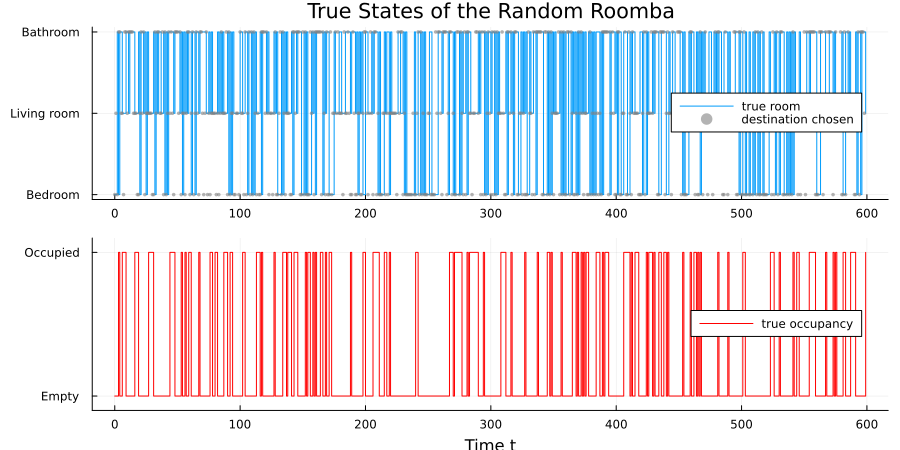

In [23]:
# true_states   = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index (1..6) of ŝ^{*[t,0]}, t = 0, ..., T
# rooms         = (true_states .+ 1) .÷ 2                      ## 1,2 → 1 (bedroom); 3,4 → 2 (livingroom); 5,6 → 3 (bathroom)
# true_occupied = iseven.(true_states)                         ## states 2, 4, 6 are occupied

# p_room = plot(0:T, rooms, linetype=:steppost, linestyle=:solid, leg=:right,
#     label="true room", title="True States of the Simulated Roomba",
#     yticks=(1:3, ["Bedroom", "Living room", "Bathroom"]))
# p_occ  = plot(0:T, true_occupied, linetype=:steppost, linestyle=:solid, leg=:right,
#     label="true occupancy", xlabel="Time t",
#     yticks=([0, 1], ["Empty", "Occupied"]), ylims=(-0.1, 1.1), color=:red)
# plot(p_room, p_occ, layout=@layout([a; b]), size=(900, 450))

true_states   = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index (1..6) of ŝ^{*[t,0]}, t = 0, ..., T
rooms         = (true_states .+ 1) .÷ 2                      ## 1,2 → 1 (bedroom); 3,4 → 2 (livingroom); 5,6 → 3 (bathroom)
true_occupied = iseven.(true_states)                         ## states 2, 4, 6 are occupied
destinations  = [argmax(Lû[0]) for Lû in parent(Lûː)]       ## chosen destination û^{[t,0]}, t = 0, ..., T-1

p_room = plot(0:T, rooms, linetype=:steppost, linestyle=:solid, leg=:right,
    label="true room", title="True States of the Random Roomba",
    yticks=(1:3, ["Bedroom", "Living room", "Bathroom"]))
scatter!(p_room, 0:T-1, destinations, markersize=2, markerstrokewidth=0, color=:gray, alpha=0.6,
    label="destination chosen")
p_occ  = plot(0:T, true_occupied, linetype=:steppost, linestyle=:solid, leg=:right,
    label="true occupancy", xlabel="Time t",
    yticks=([0, 1], ["Empty", "Occupied"]), ylims=(-0.1, 1.1), color=:red)
plot(p_room, p_occ, layout=@layout([a; b]), size=(900, 450))

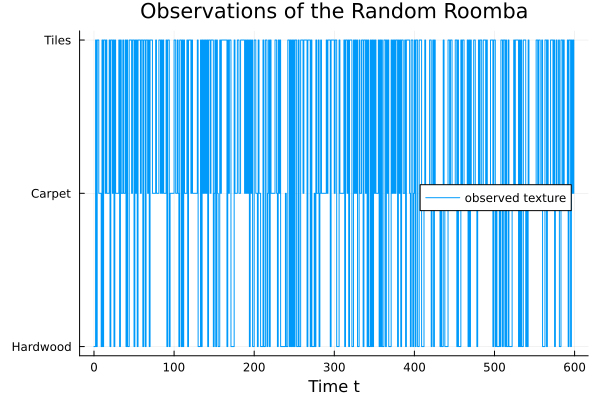

In [24]:
# textures = [argmax(Lô[0]) for Lô in parent(Lôː)]    ## texture index (1, 2, 3) of ô^{[t,0]} for t = 0, ..., T
# plot(title="Observations of the Simulated Roomba")
# plot!(
#     0:T, textures, linetype=:steppost, linestyle=:solid, leg=:right,
#     label="observed texture", xlabel="Time t", yticks=(1:3, ["Hardwood", "Carpet", "Tiles"]))

textures = [argmax(Lô[0]) for Lô in parent(Lôː)]    ## texture index (1, 2, 3) of ô^{[t,0]} for t = 0, ..., T
plot(title="Observations of the Random Roomba")
plot!(
    0:T, textures, linetype=:steppost, linestyle=:solid, leg=:right,
    label="observed texture", xlabel="Time t", yticks=(1:3, ["Hardwood", "Carpet", "Tiles"]))

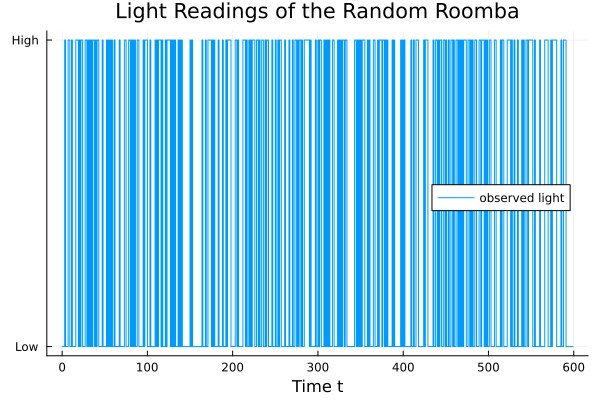

In [25]:
# lights = [argmax(Lô[1]) for Lô in parent(Lôː)]    ## light index (1 = low, 2 = high) of ô^{[t,1]} for t = 0, ..., T
# plot(title="Light Readings of the Simulated Roomba")
# plot!(
#     0:T, lights, linetype=:steppost, linestyle=:solid, leg=:right,
#     label="observed light", xlabel="Time t", yticks=(1:2, ["Low", "High"]))

lights = [argmax(Lô[1]) for Lô in parent(Lôː)]    ## light index (1 = low, 2 = high) of ô^{[t,1]} for t = 0, ..., T
plot(title="Light Readings of the Random Roomba")
plot!(
    0:T, lights, linetype=:steppost, linestyle=:solid, leg=:right,
    label="observed light", xlabel="Time t", yticks=(1:2, ["Low", "High"]))

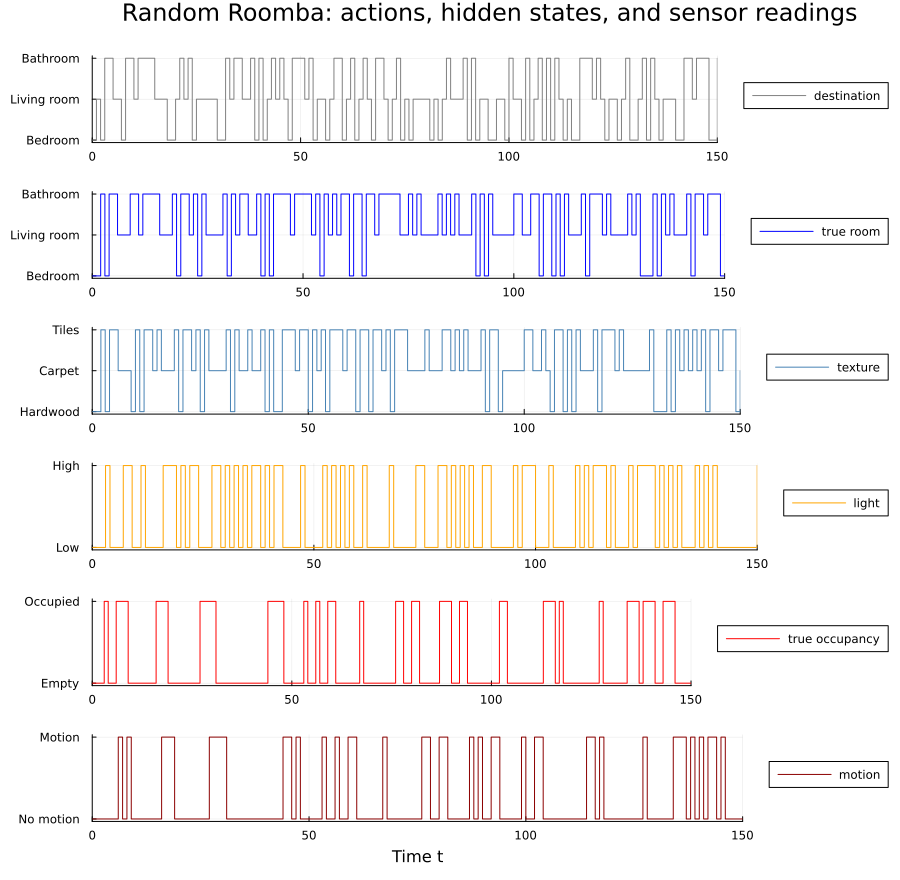

In [26]:
# true_states = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)] ## joint state index 1..6
# rooms       = (true_states .+ 1) .÷ 2               ## 1 bedroom, 2 livingroom, 3 bathroom
# occupancies = iseven.(true_states) .+ 1             ## 1 empty, 2 occupied
# textures    = [argmax(Lô[0]) for Lô in parent(Lôː)] ## 1 hardwood, 2 carpet, 3 tiles
# lights      = [argmax(Lô[1]) for Lô in parent(Lôː)] ## 1 low, 2 high
# motions     = [argmax(Lô[2]) for Lô in parent(Lôː)] ## 1 no motion, 2 motion

# window = (0, 150) ## zoom in so individual ticks are visible; use (0, T) for the full run
# panel(y, ticks, label, color) = plot(0:T, y, linetype=:steppost, label=label, color=color,
#                                      yticks=ticks, xlims=window, legend=:outerright)

# plot(
#     panel(rooms,       (1:3, ["Bedroom", "Living room", "Bathroom"]), "true room",      :blue),
#     panel(textures,    (1:3, ["Hardwood", "Carpet", "Tiles"]),        "texture",        :steelblue),
#     panel(lights,      (1:2, ["Low", "High"]),                        "light",          :orange),
#     panel(occupancies, (1:2, ["Empty", "Occupied"]),                  "true occupancy", :red),
#     panel(motions,     (1:2, ["No motion", "Motion"]),                "motion",         :darkred),
#     layout=(5, 1), size=(900, 750), link=:x, xlabel=["" "" "" "" "Time t"],
#     plot_title="Hidden states and the sensor readings that depend on them",
# )

true_states  = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index 1..6
rooms        = (true_states .+ 1) .÷ 2                      ## 1 bedroom, 2 livingroom, 3 bathroom
occupancies  = iseven.(true_states) .+ 1                    ## 1 empty, 2 occupied
textures     = [argmax(Lô[0]) for Lô in parent(Lôː)]        ## 1 hardwood, 2 carpet, 3 tiles
lights       = [argmax(Lô[1]) for Lô in parent(Lôː)]        ## 1 low, 2 high
motions      = [argmax(Lô[2]) for Lô in parent(Lôː)]        ## 1 no motion, 2 motion
destinations = [argmax(Lû[0]) for Lû in parent(Lûː)]        ## 1 bedroom, 2 livingroom, 3 bathroom (t = 0, ..., T-1)

window = (0, 150)    ## zoom in so individual ticks are visible; use (0, T) for the full run
panel(ts, y, ticks, label, color) = plot(ts, y, linetype=:steppost, label=label, color=color,
                                         yticks=ticks, xlims=window, legend=:outerright)

plot(
    panel(0:T-1, destinations, (1:3, ["Bedroom", "Living room", "Bathroom"]), "destination",    :gray),
    panel(0:T,   rooms,        (1:3, ["Bedroom", "Living room", "Bathroom"]), "true room",      :blue),
    panel(0:T,   textures,     (1:3, ["Hardwood", "Carpet", "Tiles"]),        "texture",        :steelblue),
    panel(0:T,   lights,       (1:2, ["Low", "High"]),                        "light",          :orange),
    panel(0:T,   occupancies,  (1:2, ["Empty", "Occupied"]),                  "true occupancy", :red),
    panel(0:T,   motions,      (1:2, ["No motion", "Motion"]),                "motion",         :darkred),
    layout=(6, 1), size=(900, 880), link=:x, xlabel=["" "" "" "" "" "Time t"],
    plot_title="Random Roomba: actions, hidden states, and sensor readings",
)

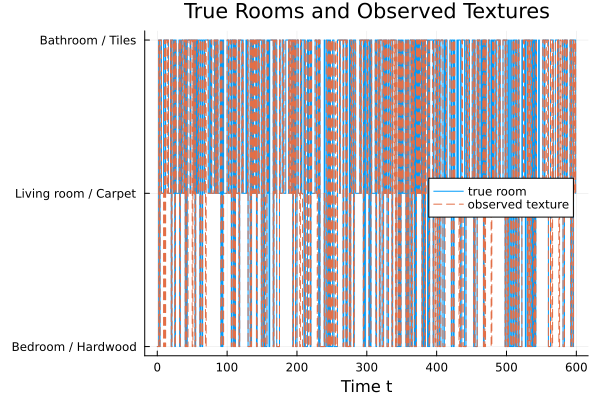

In [27]:
plot(title="True Rooms and Observed Textures")
plot!(0:T, rooms, linetype=:steppost, label="true room",
      yticks=(1:3, ["Bedroom / Hardwood", "Living room / Carpet", "Bathroom / Tiles"]))
plot!(0:T, textures, linetype=:steppost, linestyle=:dash, label="observed texture",
      xlabel="Time t", leg=:right)

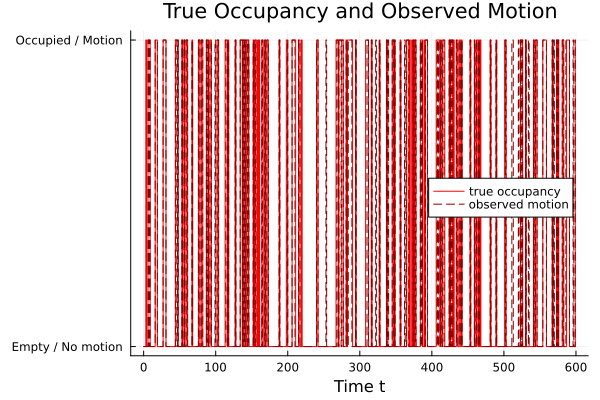

In [28]:
plot(title="True Occupancy and Observed Motion")
plot!(0:T, occupancies, linetype=:steppost, label="true occupancy", color=:red,
      yticks=(1:2, ["Empty / No motion", "Occupied / Motion"]))
plot!(0:T, motions, linetype=:steppost, linestyle=:dash, label="observed motion", color=:darkred,
      xlabel="Time t", leg=:right)

In [29]:
mistakes = count(rooms .!= textures)
println("camera mistakes: $mistakes of $(T+1) ticks ($(round(100*mistakes/(T+1), digits=1))%)")

camera mistakes: 77 of 600 ticks (12.8%)


In [30]:
occupied     = occupancies .== 2
misses       = count(occupied .& (motions .== 1))   ## person present, no motion detected
false_alarms = count(.!occupied .& (motions .== 2)) ## room empty, motion detected
println("motion sensor misses:       $misses of $(count(occupied)) occupied ticks ($(round(100*misses/count(occupied), digits=1))%)")
println("motion sensor false alarms: $false_alarms of $(count(.!occupied)) empty ticks ($(round(100*false_alarms/count(.!occupied), digits=1))%)")

motion sensor misses:       34 of 163 occupied ticks (20.9%)
motion sensor false alarms: 13 of 437 empty ticks (3.0%)


In [31]:
## The simulated fractions should come out close to 0.5, 0.85 and 0.1.
## As with the camera's mistakes, they won't be exact, because the data is a
## random sample. This uses rooms and lights from the previous plot cells,
## so run those first. A^{*[1]} has one column per joint state; room r's value
## is in column 2r-1 (empty), which equals column 2r (occupied).
for (r, room) in enumerate(["Bedroom", "Living room", "Bathroom"])
    in_room   = rooms .== r
    frac_high = mean(lights[in_room] .== 2)
    println("$room: high light $(round(frac_high, digits=2)) of $(count(in_room)) ticks (A^{*[1]}: $(LAˣ[1][2, 2r-1]))")
end

Bedroom: high light 0.55 of 142 ticks (A^{*[1]}: 0.5)
Living room: high light 0.85 of 168 ticks (A^{*[1]}: 0.85)
Bathroom: high light 0.07 of 290 ticks (A^{*[1]}: 0.1)


In [32]:
println("random Roomba, disturbance: $(round(100*mean(occupancies .== 2), digits=1))% of ticks in an occupied room")
println("random Roomba, coverage:    ",
        join(["$(r): $(round(100*mean(rooms .== i), digits=1))%" for (i, r) in enumerate(["bedroom", "livingroom", "bathroom"])], ", "))

random Roomba, disturbance: 27.2% of ticks in an occupied room
random Roomba, coverage:    bedroom: 23.7%, livingroom: 28.0%, bathroom: 48.3%


In [33]:
## ---------- random Roomba: reference values for disturbance and coverage (4.3.5) ----------
true_states_random = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index 1..6
rooms_random       = (true_states_random .+ 1) .÷ 2               ## 1 bedroom, 2 livingroom, 3 bathroom

disturbance_random = mean(iseven.(true_states_random))            ## J_disturb: fraction of ticks in an occupied room
coverage_random    = [mean(rooms_random .== r) for r in 1:3]      ## J_cover(r): fraction of ticks in each room

println("random Roomba, disturbance: $(round(100*disturbance_random, digits=1))% of ticks in an occupied room")
println("random Roomba, coverage (bedroom, livingroom, bathroom): ", round.(100 .* coverage_random, digits=1), "%")

random Roomba, disturbance: 27.2% of ticks in an occupied room
random Roomba, coverage (bedroom, livingroom, bathroom): [23.7, 28.0, 48.3]%


### 4.4 Uncertainty Model

The uncertainty in the environment is captured in the state transition array $\boldsymbol{B}^{\ast[0]}$ (factor 0, RoomOccupancy), with one transition matrix per action, and the observation generation matrices $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture), $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light) and $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion). Their entries are the probabilities of the Roomba's moves, including moves that fail, and of changes in occupancy, and of the readings of the camera, the light sensor and the motion sensor. The actions themselves add no uncertainty: the agent knows which action it chose, only not exactly what will come of it. The initial state adds no uncertainty either, because the Roomba always starts in the empty bedroom.

On the agent's side, there is no uncertainty about how the environment works: in this part, the agent is given $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$. What remains is uncertainty about the *state*: which room the Roomba is in, whether that room is occupied, and, when planning, where its actions will lead and whom it will meet there. The agent handles this uncertainty with its beliefs, and takes it into account when choosing actions.

### 4.5 Agent / Generative Model
#### 4.5.1 State and Observation variables
On the agent's side, the state of the environment at time $t$ is not known: the agent represents it by a (compound) tuple of categorical random variables, one per state factor (here a single factor):

$$
\mathbf{s}^{(t)} = \big(s^{[t,0]}\big)
$$

where the *state factors* are:

- factor 0 (RoomOccupancy):
    - $s^{[t,0]} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

The agent never observes $s^{[t,0]}$ directly. What it holds instead is a *belief*, the probability vector $\boldsymbol{s}^{[t,0]} \in [0,1]^{6}$, with one probability per combination of room and occupancy. From it, the agent's belief about the room follows by adding up the empty and occupied entries of each room, and its belief that the current room is occupied by adding up the three occupied entries.

The *initial state prior* is given by

$$
P_D\big(s^{[0,0]}\big) = \mathcal{Cat}\big(s^{[0,0]};\, \boldsymbol{D}^{[0]}\big)
$$

where $\boldsymbol{D}^{[0]} \in [0,1]^{6}$ parameterizes the categorical distribution of $s^{[0,0]}$. Unlike the environment, the agent does not know that the Roomba starts in the empty bedroom, so it uses the uniform prior $\boldsymbol{D}^{[0]} = [\tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}]^{\top}$.

The (compound) observation tuple received by the agent at time $t$ is the same one the environment generates:

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)
$$

where the *observation modalities* are:

- modality 0 (Texture):
    - $o^{[t,0]} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,0]} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$
- modality 1 (Light):
    - $o^{[t,1]} \in \{\text{low}, \text{high}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,1]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$
- modality 2 (Motion):
    - $o^{[t,2]} \in \{\text{no motion}, \text{motion}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,2]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$

New in this part, the agent also chooses actions, and it prefers some observations over others. Both are described in 4.5.2.

#### 4.5.2 Decision variables

New in this part, the agent makes decisions. At each time step, it chooses an action: the room the Roomba heads for. The agent represents its action at time $t$ by a (compound) tuple of categorical random variables, one per control factor (here a single factor):

$$
\mathbf{u}^{(t)} = \big(u^{[t,0]}\big)
$$

where the *control factors* are:

- control factor 0 (Destination), acting on state factor 0 (RoomOccupancy):
    - $u^{[t,0]} \in \{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$

Heading for the room the Roomba is already in means staying put. Unlike the state, the agent always knows which action it has taken: once chosen, the action is a realized value $\hat{\boldsymbol{u}}^{[t,0]}$, which the agent hands to the environment and also uses itself, to predict how the state will change. What the agent does *not* know is the outcome: whether the move succeeds, and whether the room it reaches is occupied.

**Policies.** To choose an action, the agent looks $H$ steps ahead. It considers candidate *policies*, i.e. sequences of $H$ actions, collected as the rows of a matrix $\boldsymbol{V}$: policy $p$ is $\pi^{[p]} = \boldsymbol{V}[p, \bullet]$, and $\boldsymbol{V}[p, \tau]$ is the action it prescribes at step $\tau = 0, \ldots, H-1$. With three possible actions per step, there are $3^H$ policies; for example, $H = 2$ gives 9 policies, such as *head for the bathroom, then stay*. The agent scores each policy by its expected free energy (see 4.5.6), turns the scores into a probability for each policy, and from those derives a probability for each possible next action. Only the first action of the chosen policy is carried out; at the next time step, the agent observes the result and plans again.

#### 4.5.3 Preference variables / Setpoints

The agent's goal is expressed as a *preference over observations*: the agent prefers to receive the observations it wants to be true. There is one preference vector per modality, collected in $\mathbf{C} = \big(\boldsymbol{C}^{[0]}, \boldsymbol{C}^{[1]}, \boldsymbol{C}^{[2]}\big)$. Each $\boldsymbol{C}^{[m]}$ is a probability vector over the observations of modality $m$, playing the role of a *setpoint*: the distribution of observations the agent would like to see.

- $\boldsymbol{C}^{[0]}$ (Texture) and $\boldsymbol{C}^{[1]}$ (Light) are flat, e.g. $\boldsymbol{C}^{[0]} = [\tfrac{1}{3}, \tfrac{1}{3}, \tfrac{1}{3}]^{\top}$: the agent has no preference for any floor type or light intensity.
- $\boldsymbol{C}^{[2]}$ (Motion) prefers *no motion*, e.g. $\boldsymbol{C}^{[2]} = [0.9, 0.1]^{\top}$: the agent would like to observe no motion 90% of the time.

The agent cannot prefer *unoccupied rooms* directly, because it never observes occupancy. Instead, it prefers the observation that indicates an unoccupied room, and chooses actions it expects to produce that observation. This is the usual way of expressing goals in active inference: preferences are stated over what the agent can sense, not over the hidden state.

How strongly the agent prefers *no motion* is set by how far $\boldsymbol{C}^{[2]}$ is from flat. When scoring a policy, the agent compares the observations it expects under that policy with its preferences (see 4.5.6), and $\log \boldsymbol{C}^{[2]}$ determines how much each expected motion reading counts: with $[0.9, 0.1]^{\top}$, observing motion is $\log(0.9/0.1) \approx 2.2$ worse than observing no motion. A more extreme preference makes the agent's choices more driven by avoiding motion, and less by reducing its uncertainty about the state.

The flat preferences for Texture and Light do not mean these sensors are useless: they still help the agent infer where the Roomba is, which it needs in order to predict where its actions will lead. They just do not make any room more attractive than another.

#### 4.5.4 State Transition and Observation Generation functions
The *state transition function* is given by

$$
P_{B^{[0]}}\big(s^{[t,0]} \mid s^{[t-1,0]}, u^{[t-1,0]}\big) = \mathcal{Cat}\big(s^{[t,0]};\, \boldsymbol{B}^{[0]}[\bullet, s^{[t-1,0]}, u^{[t-1,0]}]\big)
$$

where $\boldsymbol{B}^{[0]}[\bullet, s^{[t-1,0]}, u^{[t-1,0]}]$, the column of $\boldsymbol{B}^{[0]}$ for the previous room and occupancy, in the transition matrix of the action chosen at $t-1$, parameterizes the categorical distribution of $s^{[t,0]}$.

The *observation generation functions*, one per sensor, are given by

$$
P_{A^{[m]}}\big(o^{[t,m]} \mid s^{[t,0]}\big) = \mathcal{Cat}\big(o^{[t,m]};\, \boldsymbol{A}^{[m]}[\bullet, s^{[t,0]}]\big), \qquad m = 0, 1, 2
$$

where $\boldsymbol{A}^{[m]}[\bullet, s^{[t,0]}]$, the column of $\boldsymbol{A}^{[m]}$ for the current room and occupancy, parameterizes the categorical distribution of $o^{[t,m]}$: over textures for $m = 0$, over light intensities for $m = 1$, and over motion readings for $m = 2$. Observations do not depend on the action.

In this part, the agent is given its matrices: $\boldsymbol{A}^{[m]} = \boldsymbol{A}^{\ast[m]}$ and $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$. They are known parameters, not random variables, so they appear as subscripts.

An entry of $\boldsymbol{A}^{[m]}$ is the probability of a specific *observation* given a specific *state*, and each column of $\boldsymbol{A}^{[m]}$ is a categorical distribution over observations. The same holds for each transition matrix $\boldsymbol{B}^{[0]}[\bullet, \bullet, u]$, with the next state in place of the observation. If the state were known, its column could be selected by multiplying with the one-hot encoding of that state. The agent, however, does not know the state; it only has its belief $\boldsymbol{s}^{[t,0]}$. Multiplying with the belief gives a weighted average of the columns.

**Using the functions for inference.** After carrying out action $\hat{u}^{[t-1,0]}$, the agent predicts the new state as $\boldsymbol{B}^{[0]}[\bullet, \bullet, \hat{u}^{[t-1,0]}]\,\boldsymbol{s}^{[t-1,0]}$, and then updates this prediction with the observations it receives. Given the state, the three sensors are independent of each other, so the agent combines them by multiplying their likelihoods,

$$
P\big(o^{[t,0]}, o^{[t,1]}, o^{[t,2]} \mid s^{[t,0]}\big) = \prod_{m=0}^{2} P_{A^{[m]}}\big(o^{[t,m]} \mid s^{[t,0]}\big)
$$

so a state that explains all readings well gains belief, while a state that explains only some of them loses some. Texture and light mainly tell the rooms apart, since they depend only on the room, while motion tells *empty* from *occupied*, since it depends only on occupancy.

**Using the functions for planning.** To evaluate policy $p$, the agent applies the same functions to the future, step by step, starting from its current belief:

$$
\boldsymbol{s}_{\pi^{[p]}}^{[0,0]} = \boldsymbol{B}^{[0]}\big[\bullet, \bullet, \boldsymbol{V}[p, 0]\big]\,\boldsymbol{s}^{[t,0]},
\qquad
\boldsymbol{s}_{\pi^{[p]}}^{[\tau,0]} = \boldsymbol{B}^{[0]}\big[\bullet, \bullet, \boldsymbol{V}[p, \tau]\big]\,\boldsymbol{s}_{\pi^{[p]}}^{[\tau-1,0]} \quad (\tau > 0)
$$

$$
\boldsymbol{o}_{\pi^{[p]}}^{[\tau,m]} = \boldsymbol{A}^{[m]}\,\boldsymbol{s}_{\pi^{[p]}}^{[\tau,0]}
$$

Here $\boldsymbol{s}_{\pi^{[p]}}^{[\tau,0]}$ is the *predicted* belief about time $t + \tau + 1$ if the agent follows policy $p$, and $\boldsymbol{o}_{\pi^{[p]}}^{[\tau,m]}$ is the observation of sensor $m$ it then *expects*. No real observations are available for the future, so these predictions are never updated; they are what the agent compares with its preferences when it scores policy $p$ (see 4.5.6). For the motion sensor, for example, $\boldsymbol{o}_{\pi^{[p]}}^{[\tau,2]}$ tells the agent how likely it is to observe motion if it follows policy $p$, which is exactly what its preference for *no motion* is about.

#### 4.5.5 Implementation of the Agent / Generative Model / Internal Model
We start by specifying a probabilistic model for the agent that describes the agent's internal beliefs about the external dynamics of the environment. With control, this model has two parts. Up to the current time $t$, it describes what has happened: the states the Roomba went through, the observations it received, and the actions $\hat{u}^{[0:t-1,0]}$ the agent actually took. Beyond $t$, it describes what *could* happen over the next $H$ steps, depending on which policy $\pi^{(t)}$ the agent chooses. The generative model at time $t$ is defined as follows:

$$
\begin{aligned}
&P\big(o^{[0:t+H,0]}, o^{[0:t+H,1]}, o^{[0:t+H,2]}, s^{[0:t+H,0]}, \pi^{(t)} \mid \hat{u}^{[0:t-1,0]}\big) \\[4pt]
&\quad= \underbrace{P\big(\pi^{(t)}\big)}_{\substack{\text{policy}\\ \text{prior}}}
   \,\underbrace{P_D\big(s^{[0,0]}\big)}_{\substack{\text{state}\\ \text{prior}}}
   \prod_{t'=0}^{t+H} \prod_{m=0}^{2} \underbrace{P_{A^{[m]}}\big(o^{[t',m]} \mid s^{[t',0]}\big)}_{\substack{\text{observation-generation}\\ \text{model}}} \\[4pt]
&\qquad\times \underbrace{\prod_{t'=1}^{t} P_{B^{[0]}}\big(s^{[t',0]} \mid s^{[t'-1,0]}, \hat{u}^{[t'-1,0]}\big)}_{\text{past: actions taken}}
   \;\underbrace{\prod_{\tau=0}^{H-1} P_{B^{[0]}}\big(s^{[t+\tau+1,0]} \mid s^{[t+\tau,0]}, \boldsymbol{V}[\pi^{(t)}, \tau]\big)}_{\text{future: actions under policy } \pi^{(t)}}
\end{aligned}
$$

where $\boldsymbol{D}^{[0]}$ is the agent's uniform initial state prior from 4.5.1, and $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$ are the matrices the agent is given. All of them are known parameters, so they appear as subscripts. Unlike in Part 3, there are no parameter priors: the agent learns nothing about its matrices in this part.

The two transition products differ only in where the action comes from. In the past, the action is the one the agent actually took, $\hat{u}^{[t'-1,0]}$, a known value. In the future, it is the action $\boldsymbol{V}[\pi^{(t)}, \tau]$ that the policy prescribes at step $\tau$; since the policy is not yet chosen, it is a random variable. Step $\tau$ predicts time $t + \tau + 1$, as in 4.5.4.

The **policy prior** $P\big(\pi^{(t)}\big)$ is where the agent's preferences enter the model. In active inference, it is not chosen freely: policies are a priori more probable the lower their expected free energy,

$$
P\big(\pi^{(t)} = \pi^{[p]}\big) = \sigma\big(-\boldsymbol{G}\big)_p
$$

where $\boldsymbol{G}$ collects the expected free energies $G^{[p]}$ of the policies, which depend on the preferences $\mathbf{C}$ from 4.5.3 (see 4.5.6), and $\sigma$ is the softmax. The agent thus *expects* to act in ways that lead to its preferred observations.

As before, the product over $m$ is where the three sensors are combined: at each time step, all three observations depend on the same state $s^{[t',0]}$, and given that state, they are independent. For the future, these observations are not yet available: the agent uses their expected values, $\boldsymbol{o}_{\pi^{[p]}}^{[\tau,m]}$ from 4.5.4, to evaluate each policy.

Now it is time to build our agent. Unlike in the previous parts, the agent does not learn anything: it is given its model of the world, i.e. the observation matrices $\mathbf{A} = \mathbf{A}^{\ast}$, the transition matrices $\mathbf{B} = \mathbf{B}^{\ast}$ (one per action), the uniform initial prior $\boldsymbol{D}^{[0]}$, and its preferences $\mathbf{C}$ from 4.5.3. What it has to do is *use* this model, at every tick, in three steps.

**1. Update its belief (perception).** After the environment has carried out the previous action $\hat{u}^{[t-1,0]}$ and returned the new observations $\hat{\mathbf{o}}^{(t)}$, the agent first predicts where the Roomba is likely to be now, then corrects that prediction with what its sensors report:

$$
\boldsymbol{s}^{[t,0]} \;\propto\; \Big(\prod_{m=0}^{2} \boldsymbol{A}^{[m]\top} \hat{\boldsymbol{o}}^{[t,m]}\Big) \odot \Big(\boldsymbol{B}^{[0]}[\bullet, \bullet, \hat{u}^{[t-1,0]}]\,\boldsymbol{s}^{[t-1,0]}\Big)
$$

where $\boldsymbol{A}^{[m]\top} \hat{\boldsymbol{o}}^{[t,m]}$ picks out the row of $\boldsymbol{A}^{[m]}$ for the received observation, i.e. the likelihood of that observation under each of the six states, the products are taken entry by entry ($\odot$), and the result is normalized to sum to 1. At $t = 0$, the prediction is replaced by the initial prior $\boldsymbol{D}^{[0]}$. With known matrices and a single state factor, this is exact Bayesian filtering: no variational approximation is needed.

**2. Evaluate the policies (planning).** For each policy $\pi^{[p]}$, the agent predicts its beliefs and observations over the next $H$ steps, as in 4.5.4, and scores the policy by its expected free energy $G^{[p]}$ (see 4.5.6). The score favors policies that are expected to lead to preferred observations, i.e. *no motion*, and policies that are expected to reduce the agent's uncertainty about the state.

**3. Choose an action (decision).** The scores are turned into a posterior over policies, $Q\big(\pi^{(t)} = \pi^{[p]}\big) = \sigma\big(-\boldsymbol{G}\big)_p$, and from it into a distribution over the next action, $Q\big(u^{[t,0]}\big)$, by adding up the probabilities of all policies that start with that action. The agent then carries out the most probable action, $\hat{u}^{[t,0]}$, and the cycle repeats at the next tick.

Since the model is small, with six states, three actions and a short planning horizon, all three steps can be computed directly in Julia, without `RxInfer`: step 1 is a few matrix products, and step 2 evaluates all $3^H$ policies explicitly, e.g. 9 policies for $H = 2$. This keeps every quantity of Algorithm 18 visible in the code. `RxInfer` also supports active inference, as planning formulated as inference, which becomes attractive for larger models; this is a possible direction for a later part. Let's build the agent!

In [34]:
# @model function hidden_markov_model(o⁰ː, o¹ː, o²ː, _B, T)
#     _A⁰ ~ DirichletCollection(repeat([10.0  1.0  1.0;
#                                        1.0 10.0  1.0;
#                                        1.0  1.0 10.0], inner=(1, 2))) ## P_{ǎ^{[0]}}(A^{[0]}): Texture, trusted camera (3×6)
#     _A¹ ~ DirichletCollection(ones(2, 6))                             ## P_{ǎ^{[1]}}(A^{[1]}): Light, learned from scratch (2×6)
#     _A² ~ DirichletCollection(repeat([9.0 1.0;
#                                       1.0 9.0], outer=(1, 3)))        ## P_{ǎ^{[2]}}(A^{[2]}): Motion, motion suggests occupied (2×6)

#     sː[1]  ~ Categorical(fill(1.0/6.0, 6))  ## t = 0: P_D(s^{[0,0]}), uniform over 6 joint states
#     o⁰ː[1] ~ DiscreteTransition(sː[1], _A⁰) ## t = 0: P(o^{[0,0]} | s^{[0,0]}, A^{[0]})
#     o¹ː[1] ~ DiscreteTransition(sː[1], _A¹) ## t = 0: P(o^{[0,1]} | s^{[0,0]}, A^{[1]})
#     o²ː[1] ~ DiscreteTransition(sː[1], _A²) ## t = 0: P(o^{[0,2]} | s^{[0,0]}, A^{[2]})
#     for t in 1:T
#         sː[t+1]  ~ DiscreteTransition(sː[t], _B)     ## P_{B^{[0]}}(s^{[t,0]} | s^{[t-1,0]}), B given
#         o⁰ː[t+1] ~ DiscreteTransition(sː[t+1], _A⁰)  ## P(o^{[t,0]} | s^{[t,0]}, A^{[0]})
#         o¹ː[t+1] ~ DiscreteTransition(sː[t+1], _A¹)  ## P(o^{[t,1]} | s^{[t,0]}, A^{[1]})
#         o²ː[t+1] ~ DiscreteTransition(sː[t+1], _A²)  ## P(o^{[t,2]} | s^{[t,0]}, A^{[2]})
#     end
# end

# @constraints function hidden_markov_model_constraints()
#     q(sː, _A⁰, _A¹, _A²) = q(sː)q(_A⁰)q(_A¹)q(_A²)
# end

## ---------- the agent's model: given, not learned ----------
LA = LAˣ                                               ## A^{[m]} = A^{*[m]}, m = 0, 1, 2
LB = LBˣ                                               ## B^{[0]} = B^{*[0]}, 6×6×3 (one matrix per action)
LD = tuple0(fill(1/6, 6))                              ## D^{[0]}: uniform initial prior over the 6 joint states
LC = tuple0(fill(1/3, 3),                              ## C^{[0]}: Texture, flat
            fill(1/2, 2),                              ## C^{[1]}: Light, flat
            [0.9, 0.1])                                ## C^{[2]}: Motion, prefers no motion

## ---------- policies: all action sequences of length H ----------
H  = 2                                                 ## planning horizon
_V = [p[τ] for p in vec(collect(Iterators.product(ntuple(_ -> 1:3, H)...))), τ in 1:H]   ## P×H; column τ+1 is step τ
P  = size(_V, 1)                                       ## number of policies, 3^H

## ---------- helpers ----------
normalize(v)  = v ./ sum(v)
log_stable(x) = log.(max.(x, 1e-16))                   ## avoids log(0)
softmax(x)    = normalize(exp.(x .- maximum(x)))
LH = tuple0((-vec(sum(LA[m] .* log_stable(LA[m]), dims=1)) for m in eachindex(LA))...)   ## H[A^{[m]}]: entropy of each column

## ---------- step 1: perception (exact Bayesian filtering) ----------
## s^{[t,0]} ∝ (∏_m A^{[m]ᵀ} ô^{[t,m]}) ⊙ (B^{[0]}[•,•,û^{[t-1,0]}] s^{[t-1,0]}); at t = 0 the prediction is D^{[0]}
function perceive(Lsₜ₋₁, Lôₜ, ûₜ₋₁)
    prediction = Lsₜ₋₁ === nothing ? LD[0] : LB[0][:, :, ûₜ₋₁] * Lsₜ₋₁[0]
    likelihood = reduce((a, b) -> a .* b, (LA[m]' * Lôₜ[m] for m in eachindex(LA)))    ## ∏_m A^{[m]ᵀ} ô^{[t,m]}, entry by entry (⊙)
    tuple0(normalize(likelihood .* prediction))      ## Lsₜ = s^{(t)}
end

## ---------- step 2: expected free energy of policy p ----------
## G^{[p]} = Σ_τ Σ_m [ o_π^{[τ,m]}·(log o_π^{[τ,m]} - log C^{[m]})  +  H[A^{[m]}]·s_π^{[τ,0]} ]
##                      (risk: expected vs. preferred observations)    (ambiguity: expected sensor noise)
function efe(Lsₜ, p)
    s = Lsₜ[0]
    G = 0.0
    for τ in 1:H                                       ## code τ = math τ + 1
        s = LB[0][:, :, _V[p, τ]] * s                  ## s_π^{[τ,0]}: predicted belief
        for m in eachindex(LA)
            o  = LA[m] * s                             ## o_π^{[τ,m]}: expected observation
            G += o' * (log_stable(o) - log_stable(LC[m])) + LH[m]' * s
        end
    end
    G
end

## ---------- step 3: from policy scores to an action ----------
function plan(Lsₜ)
    _G  = [efe(Lsₜ, p) for p in 1:P]                  ## G^{[p]}, one per policy
    _qπ = softmax(-_G)                                 ## Q(π^{(t)} = π^{[p]}) = σ(-G)_p
    _qu = [sum(_qπ[_V[:, 1] .== u]) for u in 1:3]      ## Q(u^{[t,0]}): add up policies by their first action
    (_G, _qπ, _qu)
end

choose(_qu) = argmax(_qu)                              ## û^{[t,0]}: the most probable action (1 bedroom, 2 livingroom, 3 bathroom)

choose (generic function with 1 method)

**Notes on the agent code**

*Names: the code mirrors the agent's math.*

- `LA`, `LB`, `LC` and `LD` are tuples, upright bold $\mathbf{A}$, $\mathbf{B}$, $\mathbf{C}$ and $\mathbf{D}$, built with `tuple0` as in the environment. By the tear-off mnemonic, `LA[m]` is the italic-bold matrix $\boldsymbol{A}^{[m]}$, `LB[0]` the transition array $\boldsymbol{B}^{[0]}$, and `LC[m]` the preference vector $\boldsymbol{C}^{[m]}$. Since the agent is given its model, `LA` and `LB` are simply the environment's `LAˣ` and `LBˣ`, without the asterisk.
- `_V`, `_G`, `_qπ` and `_qu` are single italic-bold arrays: the policy matrix $\boldsymbol{V}$, the expected free energies $\boldsymbol{G}$, the posterior over policies $Q\big(\pi^{(t)}\big)$ and the distribution over the next action $Q\big(u^{[t,0]}\big)$.
- `Lsₜ` and `Lsₜ₋₁` are the agent's belief tuples $\mathbf{s}^{(t)}$ and $\mathbf{s}^{(t-1)}$, with `Lsₜ[0]` the belief $\boldsymbol{s}^{[t,0]}$ over the six joint states.
- `LH` holds, per modality, the entropy of each column of $\boldsymbol{A}^{[m]}$: how uncertain the sensor's reading is in each state. It is computed once, since the matrices do not change.

*Structure: one function per step.*

- `perceive` is step 1, the perception: it predicts the new state with the transition matrix of the previous action, multiplies by the likelihoods of the three received observations, and normalizes. At $t = 0$, it starts from $\boldsymbol{D}^{[0]}$ instead of a prediction. This is exact Bayesian filtering.
- `efe` is step 2, the evaluation of one policy: it rolls the belief forward through the policy's actions and sums, over the steps and the three sensors, the *risk* (how far the expected observations are from the preferences) and the *ambiguity* (how uncertain the sensors' readings are expected to be). This follows line 16 of Algorithm 18.
- `plan` and `choose` are step 3, the decision: `plan` turns the scores into the posterior over policies and the distribution over the next action, and `choose` picks the most probable action. This follows lines 19 and 20 of Algorithm 18.

*Indexing.* Tuples are 0-based as everywhere else, e.g. `LA[0]` to `LA[2]`. Inside the italic-bold arrays, Julia's ordinary 1-based indices are used: the six states, the three actions, and the planning steps. The math's step $\tau = 0, \ldots, H-1$ is column $\tau + 1$ of `_V`.

This part does not use `RxInfer`: with known matrices and a single state factor, all three steps are a few lines of Julia, which keeps every quantity of Algorithm 18 visible.

Next, we define the agent and the time-stepping procedure.

In [35]:
# function create_agent(; Lô⁰ː_data, Lô¹ː_data, Lô²ː_data, _B)
#     @assert length(Lô⁰ː_data) == length(Lô¹ː_data) == length(Lô²ː_data) "all sensors must cover the same time steps"
#     T = length(Lô⁰ː_data) - 1    ## observations at t = 0, ..., T

#     compute = () -> begin
#         imarginals = @initialization begin
#             q(_A⁰) = DirichletCollection(ones(3, 6)) ## Texture: 3 textures   × 6 joint states
#             q(_A¹) = DirichletCollection(ones(2, 6)) ## Light:   2 levels     × 6 joint states
#             q(_A²) = DirichletCollection(ones(2, 6)) ## Motion:  2 readings   × 6 joint states
#             q(sː)  = vague(Categorical, 6)
#         end
#         infer(
#             model          = hidden_markov_model(_B=_B, T=T),
#             data           = (o⁰ː = Lô⁰ː_data, o¹ː = Lô¹ː_data, o²ː = Lô²ː_data),
#             constraints    = hidden_markov_model_constraints(),
#             initialization = imarginals,
#             returnvars     = (_A⁰ = KeepLast(), _A¹ = KeepLast(), _A² = KeepLast(), sː = KeepLast()),
#             iterations     = 20,
#             free_energy    = true,
#         )
#     end

#     return compute
# end

function create_agent()
    Lsₜ₋₁ = nothing    ## s^{(t-1)}: the previous belief (none before t = 0)
    ûₜ₋₁  = nothing    ## û^{[t-1,0]}: the previous action, as an index 1..3 (none before t = 0)
    Lsₜ   = nothing    ## s^{(t)}: the current belief
    ûₜ    = nothing    ## û^{[t,0]}: the current action
    _G = _qπ = _qu = nothing    ## the current plan: G, Q(π^{(t)}), Q(u^{[t,0]})

    ## step 1 and 2: update the belief with the new observations, then score all policies
    compute = (Lôₜ) -> begin
        Lsₜ = perceive(Lsₜ₋₁, Lôₜ, ûₜ₋₁)
        _G, _qπ, _qu = plan(Lsₜ)
        nothing
    end

    ## step 3: choose the next action, returned as a one-hot action tuple û^{(t)}
    act = () -> begin
        ûₜ = choose(_qu)
        tuple0(Float64.(1:3 .== ûₜ))
    end

    ## predicted beliefs s_π^{[τ,0]}, τ = 0, ..., H-1, under policy p (for inspection)
    future = (p) -> begin
        s = Lsₜ[0]
        Lsπː = Any[]
        for τ in 1:H
            s = LB[0][:, :, _V[p, τ]] * s
            push!(Lsπː, tuple0(s))
        end
        offset0(Lsπː)
    end

    ## move one tick forward: the current belief and action become the previous ones
    slide = () -> begin
        Lsₜ₋₁ = Lsₜ
        ûₜ₋₁  = ûₜ
        nothing
    end

    belief = () -> Lsₜ                  ## s^{(t)}, for recording
    scores = () -> (_G, _qπ, _qu)       ## the current plan, for inspection

    return (compute, act, future, slide, belief, scores)
end

create_agent (generic function with 1 method)

### 4.6 Agent Evaluation
Now it's time to hand the Roomba over to the agent. Does it manage to clean the apartment while staying out of people's way?

Unlike in the previous parts, there is no separate inference step on finished data. The agent and the environment now run together, tick by tick, for $T + 1 = 600$ ticks. At each tick:

1. the environment reports the observations $\hat{\mathbf{o}}^{(t)}$ from the three sensors,
2. the agent updates its belief $\boldsymbol{s}^{[t,0]}$ about room and occupancy (`compute`, step 1),
3. the agent scores all policies by their expected free energy and chooses the next destination $\hat{\boldsymbol{u}}^{[t,0]}$ (`compute`, step 2, and `act`),
4. the environment carries out the action, moving the Roomba and updating occupancy (`execute`), and
5. the agent moves one tick forward (`slide`).

During the run, we record the true states $\hat{\mathbf{s}}^{\ast(0:T)}$, the observations $\hat{\mathbf{o}}^{(0:T)}$, the actions $\hat{\mathbf{u}}^{(0:T-1)}$ and the agent's beliefs $\boldsymbol{s}^{[0:T,0]}$. From these, we compute the measures from 4.3.5: the **disturbance** (how often the Roomba ended up in an occupied room), the **coverage** (how its time was spread over the three rooms), and the **tracking** accuracies (how well the agent knew where it was and whether it had company). The environment uses the same random seed as the random Roomba in 4.3, so the comparison with that reference point is as fair as possible: only the way the actions are chosen differs.

Since the agent is given its model of the world, there is nothing to learn and no free energy to minimize over iterations: the agent's beliefs follow from exact Bayesian filtering, and its choices from the expected free energy of its policies. Let's start the run!

#### 4.6.1 Evaluate with simulated data

##### 4.6.1.1 Naive approach {N/A}

##### 4.6.1.2 Active inference approach

In [36]:
### Simulation parameters
## Time steps t = 0, ..., T (600 ticks)
T = 599

## Initial state: the Roomba starts in the empty bedroom
## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)} = (ŝ^{*[0,0]})

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [37]:
### OVERRIDES

Let's take a look at our results. If the agent's preferences work, the Roomba should spend clearly less of its time in occupied rooms than the random Roomba from 4.3 (a lower **disturbance**), while still visiting all three rooms (a reasonable **coverage**). Behind this behavior, the agent should keep good track of where the Roomba is and whether its room is occupied (high **tracking** accuracies), since it can only avoid company it knows about.

It is also worth looking at *how* the agent behaves, not just how well. We expect it to leave a room soon after detecting motion there, to linger in rooms that stay quiet, and to prefer rooms that are rarely occupied, such as the bathroom, while still checking the others from time to time, since occupancy changes and a room that was busy may have become quiet. Let's see if it worked.

In [38]:
# ## Environment: generate t = 0, ..., T
# (execute_ai, observe_ai, state_ai) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)
# Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
# Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (Texture, Light, Motion)
# for t = 0:T
#     t > 0 && execute_ai()    ## move and observe (t = 0 is already set up)
#     Lŝˣː[t] = state_ai()
#     Lôː[t]  = observe_ai()
# end

# ## Agent: infer room and occupancy, and learn A^{[0]}, A^{[1]}, A^{[2]} from all observations at once (B^{[0]} given)
# Lô⁰ː_data  = [Lô[0] for Lô in parent(Lôː)]    ## Texture, 1-based copy for RxInfer
# Lô¹ː_data  = [Lô[1] for Lô in parent(Lôː)]    ## Light,   1-based copy for RxInfer
# Lô²ː_data  = [Lô[2] for Lô in parent(Lôː)]    ## Motion,  1-based copy for RxInfer
# compute_ai = create_agent(; Lô⁰ː_data=Lô⁰ː_data, Lô¹ː_data=Lô¹ː_data, Lô²ː_data=Lô²ː_data, _B=LBˣ[0])
# result     = compute_ai()

## Environment and agent
(execute_ai, observe_ai, state_ai) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)
(compute_ai, act_ai, future_ai, slide_ai, belief_ai, scores_ai) = create_agent()

Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (Texture, Light, Motion)
Lûː  = offset0(Vector{Any}(undef, T))      ## û^{(0:T-1)}: chosen actions, each a tuple (Destination)
Lsː  = offset0(Vector{Any}(undef, T+1))    ## s^{(0:T)}: the agent's beliefs, each a tuple (RoomOccupancy)
Lquː = offset0(Vector{Any}(undef, T+1))    ## Q(u^{[t,0]}): the agent's action probabilities at each tick

for t = 0:T
    t > 0 && execute_ai(Lûː[t-1])         ## 4. the environment carries out the previous action
    Lŝˣː[t] = state_ai()
    Lôː[t]  = observe_ai()                ## 1. the environment reports the observations
    compute_ai(Lôː[t])                    ## 2.–3. the agent updates its belief and scores the policies
    Lsː[t]  = belief_ai()
    Lquː[t] = scores_ai()[3]
    if t < T
        Lûː[t] = act_ai()                 ## 3. the agent chooses the next destination
        slide_ai()                        ## 5. the agent moves one tick forward
    end
end

In [39]:
[Lŝˣ[0] for Lŝˣ in Lŝˣː] ## ŝ^{*[t,0]} for t = 0, ..., T: the true RoomOccupancy factor (one-hot over 6 joint states)

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 ⋮
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [40]:
[action_labels[argmax(Lû[0])] for Lû in Lûː]    ## destination chosen by the agent at t = 0, ..., T-1, by name

599-element OffsetArray(::Vector{String}, 0:598) with eltype String with indices 0:598:
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "livingroom"
 ⋮
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"

In [41]:
[round.(Ls[0], digits=2) for Ls in Lsː]    ## s^{[t,0]} for t = 0, ..., T: the agent's belief over the 6 joint states

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [0.74, 0.16, 0.01, 0.0, 0.07, 0.02]
 [0.04, 0.0, 0.16, 0.03, 0.75, 0.02]
 [0.89, 0.08, 0.0, 0.0, 0.04, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.92, 0.08, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.13, 0.87, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.98, 0.02]
 [0.92, 0.08, 0.0, 0.0, 0.0, 0.0]
 [0.51, 0.01, 0.0, 0.0, 0.47, 0.01]
 ⋮
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.92, 0.08, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.36, 0.64]
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]

In [42]:
[state_labels[argmax(Lŝˣ[0])] for Lŝˣ in Lŝˣː] ## true state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-occupied"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 ⋮
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"

In [43]:
[state_labels[argmax(Ls[0])] for Ls in Lsː]    ## the agent's most probable state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-occupied"
 "bathroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 ⋮
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-occupied"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"

In [44]:
## t, true state, agent's most probable state, destination chosen (none at t = T)
[(t,
  state_labels[argmax(Lŝˣː[t][0])],
  state_labels[argmax(Lsː[t][0])],
  t < T ? action_labels[argmax(Lûː[t][0])] : "-")
 for t in 0:T]

600-element Vector{Tuple{Int64, String, String, String}}:
 (0, "bedroom-empty", "bedroom-empty", "livingroom")
 (1, "bathroom-empty", "bathroom-empty", "bedroom")
 (2, "bedroom-empty", "bedroom-empty", "livingroom")
 (3, "bathroom-empty", "bathroom-empty", "bedroom")
 (4, "bedroom-empty", "bedroom-empty", "livingroom")
 (5, "bathroom-empty", "bathroom-empty", "bedroom")
 (6, "bedroom-occupied", "bedroom-occupied", "livingroom")
 (7, "bathroom-empty", "bathroom-empty", "bedroom")
 (8, "bedroom-empty", "bedroom-empty", "livingroom")
 (9, "bathroom-empty", "bedroom-empty", "livingroom")
 ⋮
 (591, "bedroom-empty", "bedroom-empty", "livingroom")
 (592, "bathroom-empty", "bathroom-empty", "bedroom")
 (593, "bedroom-empty", "bedroom-empty", "livingroom")
 (594, "bathroom-empty", "bathroom-empty", "bedroom")
 (595, "bedroom-empty", "bedroom-empty", "livingroom")
 (596, "bathroom-empty", "bathroom-occupied", "bedroom")
 (597, "bedroom-empty", "bedroom-empty", "livingroom")
 (598, "bathroom-empt

In [45]:
[Lô[0] for Lô in Lôː] ## ô^{[t,0]} for t = 0, ..., T: the received Texture observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]

In [46]:
[Lô[1] for Lô in Lôː] ## ô^{[t,1]} for t = 0, ..., T: the received Light observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [47]:
[Lô[2] for Lô in Lôː] ## ô^{[t,2]} for t = 0, ..., T: the received Motion observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [48]:
## result.posteriors
Lsː    ## s^{(0:T)}: the agent's belief at each tick (replaces result.posteriors[:sː])

600-element OffsetArray(::Vector{Any}, 0:599) with eltype Any with indices 0:599:
 [[0.7397793640493185, 0.1557430240103829, 0.012329656067488641, 0.0025957170668397147, 0.07397793640493187, 0.015574302401038288]]
 [[0.04089014658863846, 0.0021229515558785347, 0.1606683564738941, 0.02798796683063163, 0.7505635736506718, 0.017767004900285432]]
 [[0.8854463138119684, 0.07533431110306626, 0.000438496772681376, 1.9731539345333495e-5, 0.03796538087569698, 0.0007957658972417582]]
 [[0.0032621093457326313, 9.068775620376353e-5, 0.00020595342676058096, 4.243891010171673e-5, 0.9736598933448355, 0.02273891721636581]]
 [[0.9161466515437152, 0.08232741482866807, 2.741793128510156e-6, 1.4002491831901665e-7, 0.0014994854952288202, 2.3566314340826935e-5]]
 [[0.003264582762405992, 9.379574433394626e-5, 7.669286303840491e-6, 1.60905845887899e-6, 0.9738537196502823, 0.022778623498214946]]
 [[0.12719629636675175, 0.8687020079757494, 2.5018820624112817e-9, 9.84591275986226e-9, 0.0018697050442159624, 0.002

In [49]:
_G, _qπ, _qu = scores_ai()                           ## the agent's plan at the last tick, t = T
[(join(action_labels[_V[p, :]], " → "), round(_G[p], digits=2), round(_qπ[p], digits=3)) for p in 1:P]

9-element Vector{Tuple{String, Float64, Float64}}:
 ("bedroom → bedroom", 4.09, 0.081)
 ("livingroom → bedroom", 3.69, 0.121)
 ("bathroom → bedroom", 3.75, 0.113)
 ("bedroom → livingroom", 3.82, 0.106)
 ("livingroom → livingroom", 3.62, 0.129)
 ("bathroom → livingroom", 3.66, 0.124)
 ("bedroom → bathroom", 3.82, 0.106)
 ("livingroom → bathroom", 3.76, 0.113)
 ("bathroom → bathroom", 3.8, 0.108)

In [50]:
# println("Transition matrix B^{[0]} (RoomOccupancy), given to the agent:")
# LBˣ[0]    ## B^{[0]} = B^{*[0]}, not learned in this part

This compares well with:
```
LBˣ[0] = [
0.9  0.0  0.1;
0.0  0.9  0.1;
0.1  0.1  0.8]
```



In [51]:
# println("Posterior mean of A^{[0]} (Texture likelihood):")
# _Ā⁰ = mean(result.posteriors[:_A⁰]) ## Ā^{[0]} = E_Q[A^{[0]}], the agent's estimate of A^{*[0]}

<!-- This compares well with:
```
LAˣ[0] = [
0.9  0.05 0.05;
0.05 0.9  0.05;
0.05 0.05 0.9] 
``` -->

This compares well with:
```
LAˣ[0] = [
0.9  0.9  0.05 0.05 0.05 0.05;
0.05 0.05 0.9  0.9  0.05 0.05;
0.05 0.05 0.05 0.05 0.9  0.9 ]
```

In [52]:
# println("Posterior mean of A^{[1]} (Light likelihood):")
# _Ā¹ = mean(result.posteriors[:_A¹])    ## Ā^{[1]} = E_Q[A^{[1]}], the agent's estimate of A^{*[1]} (2×6)

<!-- This compares well with:
```
LAˣ[1] = [
0.5  0.15 0.9;
0.5  0.85 0.1]
``` -->

This compares well with:
```
LAˣ[1] = [
0.5  0.5  0.15 0.15 0.9  0.9;
0.5  0.5  0.85 0.85 0.1  0.1]
```

In [53]:
# println("Posterior mean of A^{[2]} (Motion likelihood):")
# _Ā² = mean(result.posteriors[:_A²])    ## Ā^{[2]} = E_Q[A^{[2]}], the agent's estimate of A^{*[2]} (2×6)

This compares well with:
```
LAˣ[2] = [
0.95 0.2  0.95 0.2  0.95 0.2;
0.05 0.8  0.05 0.8  0.05 0.8]
```

Finally, we can check whether the agent achieved what it was built for: keeping the Roomba out of people's way while still cleaning the apartment. From the true states $\hat{\boldsymbol{s}}^{\ast[t,0]}$, we compute the **disturbance**, the fraction of ticks the Roomba spent in an occupied room, and compare it with that of the random Roomba from 4.3; and the **coverage**, the fraction of ticks it spent in each room.

Behind this behavior lies the agent's tracking. From its belief $\boldsymbol{s}^{[t,0]}$ over the six joint states, we derive its most probable room at each tick and its probability that the room is occupied, and compare both with the true state. We expect the room to be tracked about as well as in Parts 2 and 3, since the camera still does most of that work. For occupancy, a natural question is whether the agent can do better than the motion sensor alone: occupancy usually persists while the Roomba stays in a room, so a single missed person or false alarm *could* be overruled by the readings around it. Tracking matters more now than before: when the agent thinks a room is empty while it is not, it will stay where it causes disturbance.

There is no free energy curve to check this time: the agent's beliefs come from exact Bayesian filtering at each tick, not from an iterative approximation.

disturbance: agent 17.3%, random Roomba 27.2%
coverage (bedroom, livingroom, bathroom): agent [44.3, 6.3, 49.3]%, random Roomba [23.7, 28.0, 48.3]%
camera misread the floor at 63 of 600 ticks; agent still inferred the right room at 65.1% of those
motion sensor was wrong at 38 of 600 ticks; agent still inferred the right occupancy at 0.0% of those


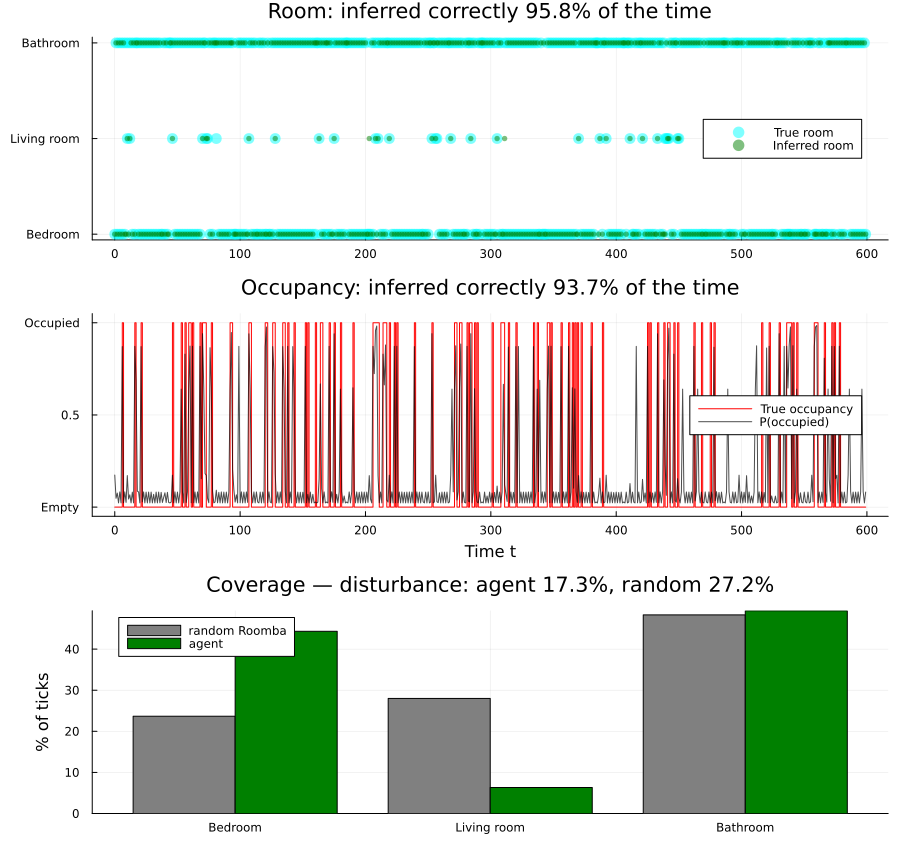

In [54]:
# Lqsː = offset0(result.posteriors[:sː])    ## Q(s^{[t,0]}) over 6 joint states, t = 0, ..., T (0-based)

# ## from joint states to room and occupancy (state order: room by room, empty before occupied)
# room_of(p) = [p[1]+p[2], p[3]+p[4], p[5]+p[6]] ## marginal over rooms
# occ_of(p)  = p[2] + p[4] + p[6]                ## probability that the room is occupied

# true_states    = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)] ## true joint state index 1..6
# rooms          = (true_states .+ 1) .÷ 2                  ## true room: 1 bedroom, 2 livingroom, 3 bathroom
# true_occupied  = iseven.(true_states)                     ## true occupancy

# q_states       = [ReactiveMP.probvec(q) for q in parent(Lqsː)]
# inferred_rooms = [argmax(room_of(p)) for p in q_states] ## most probable room under Q(s^{[t,0]})
# p_occupied     = [occ_of(p) for p in q_states]          ## agent's probability that the room is occupied
# inferred_occ   = p_occupied .> 0.5

# accuracy_room = mean(inferred_rooms .== rooms)
# accuracy_occ  = mean(inferred_occ .== true_occupied)

# ## where the camera misread the floor, did the agent still get the room right?
# textures            = [argmax(Lô[0]) for Lô in parent(Lôː)]
# camera_wrong        = textures .!= rooms
# accuracy_cam_wrong  = mean(inferred_rooms[camera_wrong] .== rooms[camera_wrong])
# println("camera misread the floor at $(count(camera_wrong)) of $(T+1) ticks; ",
#         "agent still inferred the right room at $(round(100*accuracy_cam_wrong, digits=1))% of those")

# ## where the motion sensor was wrong, did the agent still get occupancy right?
# motion_detected     = [argmax(Lô[2]) for Lô in parent(Lôː)] .== 2
# motion_wrong        = motion_detected .!= true_occupied
# accuracy_mot_wrong  = mean(inferred_occ[motion_wrong] .== true_occupied[motion_wrong])
# println("motion sensor was wrong at $(count(motion_wrong)) of $(T+1) ticks; ",
#         "agent still inferred the right occupancy at $(round(100*accuracy_mot_wrong, digits=1))% of those")

# p1 = scatter(0:T, rooms,
#     title="Room: inferred correctly $(round(100*accuracy_room, digits=1))% of the time",
#     label="True room", legend=:right,
#     yticks=(1:3, ["Bedroom", "Living room", "Bathroom"]),
#     markercolor=:cyan, markersize=6, markerstrokewidth=0, alpha=.5)
# scatter!(p1, 0:T, inferred_rooms,
#     label="Inferred room", markercolor=:green, markersize=3, markerstrokewidth=0, alpha=.5)

# p2 = plot(0:T, true_occupied, linetype=:steppost, color=:red, label="True occupancy",
#     title="Occupancy: inferred correctly $(round(100*accuracy_occ, digits=1))% of the time",
#     yticks=([0, 0.5, 1], ["Empty", "0.5", "Occupied"]), ylims=(-0.05, 1.05), legend=:right)
# plot!(p2, 0:T, p_occupied, color=:black, alpha=0.7, label="P(occupied)", xlabel="Time t")

# p3 = plot(result.free_energy, label="Bethe free energy", xlabel="Iteration")

# plot(p1, p2, p3, layout=@layout([a; b; c]), size=(900, 800))

Lqsː = Lsː    ## the agent's beliefs s^{[t,0]}, t = 0, ..., T (0-based; recorded during the run)

## from joint states to room and occupancy (state order: room by room, empty before occupied)
room_of(p) = [p[1]+p[2], p[3]+p[4], p[5]+p[6]]    ## marginal over rooms
occ_of(p)  = p[2] + p[4] + p[6]                    ## probability that the room is occupied

true_states    = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)]    ## true joint state index 1..6
rooms          = (true_states .+ 1) .÷ 2                      ## true room: 1 bedroom, 2 livingroom, 3 bathroom
true_occupied  = iseven.(true_states)                         ## true occupancy

q_states       = [Ls[0] for Ls in parent(Lqsː)]               ## the agent's belief over the 6 joint states
inferred_rooms = [argmax(room_of(p)) for p in q_states]       ## most probable room
p_occupied     = [occ_of(p) for p in q_states]                ## agent's probability that the room is occupied
inferred_occ   = p_occupied .> 0.5

## ---------- behavior: disturbance and coverage (4.3.5) ----------
disturbance = mean(true_occupied)
coverage    = [mean(rooms .== r) for r in 1:3]
println("disturbance: agent $(round(100*disturbance, digits=1))%, random Roomba $(round(100*disturbance_random, digits=1))%")
println("coverage (bedroom, livingroom, bathroom): agent ", round.(100 .* coverage, digits=1),
        "%, random Roomba ", round.(100 .* coverage_random, digits=1), "%")

## ---------- tracking ----------
accuracy_room = mean(inferred_rooms .== rooms)
accuracy_occ  = mean(inferred_occ .== true_occupied)

textures           = [argmax(Lô[0]) for Lô in parent(Lôː)]
camera_wrong       = textures .!= rooms
accuracy_cam_wrong = mean(inferred_rooms[camera_wrong] .== rooms[camera_wrong])
println("camera misread the floor at $(count(camera_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right room at $(round(100*accuracy_cam_wrong, digits=1))% of those")

motion_detected    = [argmax(Lô[2]) for Lô in parent(Lôː)] .== 2
motion_wrong       = motion_detected .!= true_occupied
accuracy_mot_wrong = mean(inferred_occ[motion_wrong] .== true_occupied[motion_wrong])
println("motion sensor was wrong at $(count(motion_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right occupancy at $(round(100*accuracy_mot_wrong, digits=1))% of those")

## ---------- plots ----------
p1 = scatter(0:T, rooms,
    title="Room: inferred correctly $(round(100*accuracy_room, digits=1))% of the time",
    label="True room", legend=:right,
    yticks=(1:3, ["Bedroom", "Living room", "Bathroom"]),
    markercolor=:cyan, markersize=6, markerstrokewidth=0, alpha=.5)
scatter!(p1, 0:T, inferred_rooms,
    label="Inferred room", markercolor=:green, markersize=3, markerstrokewidth=0, alpha=.5)

p2 = plot(0:T, true_occupied, linetype=:steppost, color=:red, label="True occupancy",
    title="Occupancy: inferred correctly $(round(100*accuracy_occ, digits=1))% of the time",
    yticks=([0, 0.5, 1], ["Empty", "0.5", "Occupied"]), ylims=(-0.05, 1.05), legend=:right)
plot!(p2, 0:T, p_occupied, color=:black, alpha=0.7, label="P(occupied)", xlabel="Time t")

x = 1:3
p3 = bar(x .- 0.2, 100 .* coverage_random, bar_width=0.4, label="random Roomba", color=:gray)
bar!(p3, x .+ 0.2, 100 .* coverage, bar_width=0.4, label="agent", color=:green,
    xticks=(x, ["Bedroom", "Living room", "Bathroom"]), ylabel="% of ticks",
    title="Coverage — disturbance: agent $(round(100*disturbance, digits=1))%, random $(round(100*disturbance_random, digits=1))%",
    legend=:topleft)

plot(p1, p2, p3, layout=@layout([a; b; c]), size=(900, 850))

### 4.7 Conclusion and outlook

In this part, the agent took control. Instead of watching a Roomba that moves at random, it chose at every tick where the Roomba should go next, guided by a single preference: to observe *no motion*, i.e. to stay out of people's way. Four ingredients made this possible:

- **Actions and action-dependent transitions.** The agent chooses a destination, and the transition model $\boldsymbol{B}^{[0]}$ now holds one matrix per action, describing where each move is likely to take the Roomba, including moves that fail and the detour through the bathroom.
- **Preferences over observations.** The agent cannot see whether a room is occupied, so its goal is expressed over what it can sense: a preference vector $\boldsymbol{C}^{[2]}$ that favors *no motion*.
- **Planning by expected free energy.** For every sequence of $H$ moves, the agent predicts where the Roomba will end up and what it will observe there, and scores the sequence by how far those observations are from its preferences, plus how uncertain they are. It then carries out the first move of the best sequences and plans again at the next tick.
- **An online loop.** Agent and environment now interact step by step, which filled in the remaining functions of the structure: `compute()`, `act()`, `future()` and `slide()`.

Since the agent was given its model of the world, all of this could be written directly in Julia, with exact Bayesian filtering for perception and an explicit evaluation of all policies for planning, keeping every quantity of Algorithm 18 visible.

**The preference works.** The agent spent 17.3% of its ticks in an occupied room, against 27.2% for the random Roomba in the same environment: about a third less disturbance. The coverage shows how it achieved this. It largely avoided the living room, the room most often occupied, spending only 6.3% of its time there against 28.0% for the random Roomba, and used that time in the bedroom instead (44.3% against 23.7%). Its share of the bathroom, the room least often occupied, stayed at about half (49.3% against 48.3%), since the bathroom is also the passage between the other two rooms.

**Tracking: the room carries over, occupancy does not.** The agent inferred the room correctly 95.8% of the time. Even when the camera misread the floor, which happened at 63 ticks, it still got the room right 65.1% of the time, because the room carries over from tick to tick: the agent knows where it was heading. Occupancy was inferred correctly 93.7% of the time, but here the picture is different. The motion sensor was wrong at 38 ticks, and the agent was wrong at exactly those ticks, every time: its occupancy belief simply followed the latest motion reading.

This is a consequence of the agent's own behavior. Persistence of occupancy only helps when the Roomba *stays* in a room, so that earlier readings support the current one. But the agent kept moving between the bedroom and the bathroom, and each time it enters a room, that room's occupancy is drawn fresh: the agent has no history for it. Its belief then rests on a single motion reading against the room's base rate, and that one reading usually decides. In the bathroom, for example, a false alarm moves the agent's probability of *occupied* from 0.1 to about 0.64. By moving around, the agent gives up evidence it would otherwise have gathered by staying. Here, control and perception interact.

**And it does not clean the whole apartment.** The agent's only goal is to avoid company; nothing in its preferences asks it to *clean*. The living room is therefore hardly visited at all. For a cleaning robot, that is not acceptable: the room most in use is also likely the one that needs cleaning most. Avoiding people and covering the apartment are two goals, and the agent currently has only one of them.

These results come from a single run of 600 ticks, so the exact percentages should not be over-interpreted. The difference with the random Roomba is large, though, and the patterns, avoiding the busiest room, and an occupancy belief that follows the motion sensor, follow directly from the model.

**Possible next steps:**

- **A cleaning goal.** Adding a state factor for how dirty each room is, which grows over time and is reset by cleaning, together with a preference for clean rooms, would make the agent balance two goals: cleaning where it is needed, and not disturbing anyone. It would then visit the living room when it is quiet, rather than avoiding it altogether. This is also a natural step towards the scheduling project this series is building up to.
- **Valuing information.** Staying in a room for a moment longer would give the agent a second motion reading, and with it a much more reliable picture of occupancy. A longer planning horizon, or a stronger weight on reducing uncertainty, may make the agent value this.
- **Learning while acting.** Here, the agent was given its matrices. Letting it learn $\mathbf{A}$ and $\mathbf{B}$ while it acts, as it learned $\mathbf{A}$ in Part 3, brings in the trade-off between exploring to learn and exploiting what it already knows.
- **Tuning and robustness.** The planning horizon $H$, the strength of the preference $\boldsymbol{C}^{[2]}$, and a precision parameter for how decisively the agent picks the best policy all shape its behavior. They are worth exploring systematically, with results averaged over several random seeds.
- **Planning as inference with RxInfer.** For larger models, where evaluating all policies explicitly becomes too expensive, formulating planning as inference in `RxInfer` is the natural next tool.

With this part, the Roomba is no longer just tracked: it chooses to avoid company. The next step is to make it want to clean as well.